**Persiapan Instrumen dan Pemanggilan Model**

In [1]:
!pip install roboflow

import os
from roboflow import Roboflow

rf = Roboflow(api_key="3wZ1HEwzSwHhFGO7FLwv")
project = rf.workspace("projects-bewom").project("final_cinnamon")
dataset = project.version(1).download("folder")

# Persiapkan dataset external test (cinnamon-multiple-diseases) jika belum ada di /kaggle/input
has_ext = os.path.exists('/kaggle/input') and any('_classes.csv' in files for _, _, files in os.walk('/kaggle/input'))
if not has_ext:
    try:
        print("\nMempersiapkan dataset external test (cinnamon-multiple-diseases)...")
        ext_project = rf.workspace("kalhara-vithanage").project("cinnamon-multiple-diseases")
        ext_dataset = ext_project.version(1).download("multiclass")
        print("✅ Dataset external test siap digunakan.")
    except Exception as e:
        print(f"Catatan: Pre-download external test via API dilewati ({e}), akan ditangani otomatis di Cell 10.")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 378.3/378.3 kB 10.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 88.7 MB/s eta 0:00:00
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Final_Cinnamon-1 in folder:: 100%|██████████| 7258/7258 [00:01<00:00, 4782.93it/s]


In [2]:
import zipfile
import os

zip_path = '/kaggle/working/Final_Cinnamon-1/roboflow.zip'

if os.path.exists(zip_path):
    try:
        with zipfile.ZipFile(zip_path, 'r') as zip_ref:
            bad_file = zip_ref.testzip()  # None kalau semua file dalam zip valid
            if bad_file:
                print(f"⚠️ Ada file rusak di dalam zip: {bad_file}")
            else:
                print("✅ File zip valid dan lengkap, aman untuk diekstrak.")
                zip_ref.extractall('/kaggle/working/Final_Cinnamon-1')
                print("Ekstraksi selesai. Isi folder:", os.listdir('/kaggle/working/Final_Cinnamon-1'))
    except zipfile.BadZipFile:
        print("❌ File zip rusak/tidak lengkap. Download ulang Cell 0 diperlukan.")
else:
    print("Dataset sudah dalam bentuk folder (tidak ada file zip), tidak perlu ekstraksi.")

Dataset sudah dalam bentuk folder (tidak ada file zip), tidak perlu ekstraksi.


In [3]:
import os

# Definisikan path ke folder train
train_path = '/kaggle/working/Final_Cinnamon-1/train'

# Hitung jumlah gambar per kelas
for folder in sorted(os.listdir(train_path)):
    folder_full_path = os.path.join(train_path, folder)
    if os.path.isdir(folder_full_path):
        num_images = len(os.listdir(folder_full_path))
        print(f"Kelas {folder}: {num_images} gambar")

Kelas healthy: 1430 gambar
Kelas leafspot: 1063 gambar
Kelas noncinnamon_bark: 660 gambar
Kelas noncinnamon_leaves: 497 gambar
Kelas roughbark: 1517 gambar
Kelas stripecanker: 1427 gambar


In [4]:
import os
import shutil
from sklearn.model_selection import train_test_split

def get_base_name(fname):
    return fname.split('.rf.')[0] if '.rf.' in fname else fname

orig_train_dir = '/kaggle/working/Final_Cinnamon-1/train'
new_base = '/kaggle/working/dataset_split_clean'

# Hapus hasil split lama agar tidak ada file sisa
if os.path.exists(new_base):
    shutil.rmtree(new_base)

# ============================================================
# 1. Kumpulkan SEMUA gambar dan kelompokkan berdasarkan base name
# ============================================================
groups = {}

for cls in sorted(os.listdir(orig_train_dir)):
    cls_path = os.path.join(orig_train_dir, cls)

    if not os.path.isdir(cls_path):
        continue

    for fname in os.listdir(cls_path):

        fpath = os.path.join(cls_path, fname)
        base_name = get_base_name(fname)

        groups.setdefault(base_name, []).append({
            'path': fpath,
            'class': cls,
            'fname': fname
        })

n_raw_images = sum(len(items) for items in groups.values())
print(f"Total gambar mentah : {n_raw_images}")
print(f"Total group unik    : {len(groups)}")

# ============================================================
# 2. Deteksi group yang memiliki konflik kelas
# ============================================================
conflicting_groups = []

for base_name, items in groups.items():

    classes = set(item['class'] for item in items)

    if len(classes) > 1:
        conflicting_groups.append({
            'base_name': base_name,
            'classes': sorted(classes),
            'files': [item['fname'] for item in items]
        })

print(f"Group dengan konflik kelas: {len(conflicting_groups)}")

# ============================================================
# 3. Keluarkan group konflik dari dataset split
# ============================================================
conflicting_base_names = {
    item['base_name']
    for item in conflicting_groups
}

# Alur gambar dikeluarkan vs dipakai
n_removed_images = sum(len(groups[b]) for b in conflicting_base_names)
n_kept_images = n_raw_images - n_removed_images
print(f"Group konflik dikeluarkan : {len(conflicting_base_names)} group ({n_removed_images} gambar)")
print(f"Gambar yang dipakai       : {n_kept_images}")

print("\n" + "=" * 60)
print("PENANGANAN GROUP DENGAN KONFLIK LABEL")
print("=" * 60)

print(
    f"Total group konflik yang DIKELUARKAN dari dataset split: "
    f"{len(conflicting_base_names)}"
)

for base_name in sorted(conflicting_base_names):
    classes = next(
        item['classes']
        for item in conflicting_groups
        if item['base_name'] == base_name
    )

    print(f"  - {base_name}: {classes}")

print("\n⚠️ Group konflik TIDAK dihapus dari dataset asli.")
print("⚠️ Group konflik hanya TIDAK dimasukkan ke dataset_split_clean.")

# ============================================================
# 4. Buat daftar group berdasarkan kelas
#    Group konflik DILEWATI
# ============================================================
class_groups = {}

for base_name, items in groups.items():

    # Jangan masukkan group yang memiliki konflik kelas
    if base_name in conflicting_base_names:
        continue

    # Karena group sudah lolos pemeriksaan konflik,
    # semua file dalam group memiliki kelas yang sama
    cls = items[0]['class']

    class_groups.setdefault(cls, []).append(base_name)

print("\n===== JUMLAH GROUP SETELAH KONFLIK DIKELUARKAN =====")

for cls in sorted(class_groups.keys()):
    print(f"{cls}: {len(class_groups[cls])} groups")

# ============================================================
# 5. Split setiap kelas berdasarkan GROUP
#    80% train - 10% validation - 10% test
# ============================================================
split_map = {
    'train': {},
    'val': {},
    'test': {}
}

for cls in sorted(class_groups.keys()):

    base_names = class_groups[cls]

    train_bases, temp_bases = train_test_split(
        base_names,
        test_size=0.20,
        random_state=42
    )

    val_bases, test_bases = train_test_split(
        temp_bases,
        test_size=0.50,
        random_state=42
    )

    split_map['train'][cls] = train_bases
    split_map['val'][cls] = val_bases
    split_map['test'][cls] = test_bases

    print(
        f"{cls}: "
        f"train={len(train_bases)}, "
        f"val={len(val_bases)}, "
        f"test={len(test_bases)} groups"
    )

# ============================================================
# 6. Copy file ke folder train / val / test
# ============================================================
for split in ['train', 'val', 'test']:

    for cls, base_names in split_map[split].items():

        out_dir = os.path.join(new_base, split, cls)
        os.makedirs(out_dir, exist_ok=True)

        for base_name in base_names:

            for item in groups[base_name]:

                src = item['path']
                dst = os.path.join(out_dir, item['fname'])

                shutil.copy2(src, dst)

# ============================================================
# 7. Verifikasi jumlah gambar
# ============================================================
print("\n" + "=" * 60)
print("JUMLAH GAMBAR HASIL SPLIT")
print("=" * 60)

for split in ['train', 'val', 'test']:

    print(f"\n{split.upper()}")

    split_dir = os.path.join(new_base, split)

    total = 0

    for cls in sorted(os.listdir(split_dir)):

        cls_path = os.path.join(split_dir, cls)

        if not os.path.isdir(cls_path):
            continue

        count = len([
            f for f in os.listdir(cls_path)
            if os.path.isfile(os.path.join(cls_path, f))
        ])

        total += count

        print(f"  {cls}: {count}")

    print(f"  TOTAL: {total}")

# ============================================================
# 8. Verifikasi tidak ada group overlap
# ============================================================
train_groups = set()
val_groups = set()
test_groups = set()

for split, target_set in [
    ('train', train_groups),
    ('val', val_groups),
    ('test', test_groups)
]:

    split_dir = os.path.join(new_base, split)

    for cls in os.listdir(split_dir):

        cls_path = os.path.join(split_dir, cls)

        if not os.path.isdir(cls_path):
            continue

        for fname in os.listdir(cls_path):

            target_set.add(get_base_name(fname))

print("\n" + "=" * 60)
print("VERIFIKASI GROUP LEAKAGE")
print("=" * 60)

print("Train groups:", len(train_groups))
print("Val groups  :", len(val_groups))
print("Test groups :", len(test_groups))

print("Train ∩ Val :", len(train_groups & val_groups))
print("Train ∩ Test:", len(train_groups & test_groups))
print("Val ∩ Test  :", len(val_groups & test_groups))

# ============================================================
# 9. Pastikan tidak ada leakage
# ============================================================
if (
    train_groups & val_groups or
    train_groups & test_groups or
    val_groups & test_groups
):
    raise ValueError("❌ GROUP LEAKAGE TERDETEKSI!")

print("\n✅ Tidak ada group yang overlap.")
print("✅ Semua group konflik telah dikeluarkan.")
print("✅ Dataset berhasil dibuat dengan group-based splitting.")

# ============================================================
# STATISTIK GROUP DAN GAMBAR PER SUBSET
# ============================================================
import pandas as pd
rows = []
for split in ['train', 'val', 'test']:
    for cls in sorted(split_map[split]):
        bases = split_map[split][cls]
        rows.append({'split': split, 'class': cls,
                     'groups': len(bases),
                     'images': sum(len(groups[b]) for b in bases)})
df_group_stats = pd.DataFrame(rows)
print("\n===== STATISTIK JUMLAH GROUP & GAMBAR PER SUBSET =====")
print(df_group_stats.pivot(index='class', columns='split', values=['groups', 'images']))
df_group_stats.to_csv('/kaggle/working/group_split_statistics.csv', index=False)
assert n_kept_images == df_group_stats['images'].sum()


Total gambar mentah : 6594
Total group unik    : 1586
Group dengan konflik kelas: 19
Group konflik dikeluarkan : 19 group (184 gambar)
Gambar yang dipakai       : 6410

PENANGANAN GROUP DENGAN KONFLIK LABEL
Total group konflik yang DIKELUARKAN dari dataset split: 19
  - IMG_1566_jpg: ['noncinnamon_bark', 'roughbark', 'stripecanker']
  - IMG_1584_jpg: ['noncinnamon_bark', 'stripecanker']
  - IMG_1606_jpg: ['noncinnamon_bark', 'stripecanker']
  - IMG_1612_jpg: ['noncinnamon_bark', 'stripecanker']
  - IMG_1613_jpg: ['noncinnamon_bark', 'stripecanker']
  - IMG_1621_jpg: ['noncinnamon_bark', 'stripecanker']
  - IMG_1623_jpg: ['noncinnamon_bark', 'stripecanker']
  - IMG_1625_jpg: ['noncinnamon_bark', 'stripecanker']
  - IMG_1874_jpg: ['noncinnamon_bark', 'stripecanker']
  - IMG_1875_jpg: ['noncinnamon_bark', 'stripecanker']
  - IMG_1965_jpg: ['noncinnamon_bark', 'roughbark']
  - IMG_20220815_160719_jpg: ['healthy', 'leafspot']
  - IMG_20220816_130726_jpg: ['healthy', 'leafspot']
  - IMG_2044

Total gambar training: 5136
Gambar ditandai rusak berat (blur/noise ekstrem): 737
class
healthy               243
leafspot              129
noncinnamon_bark      205
noncinnamon_leaves      4
roughbark              46
stripecanker          110
dtype: int64


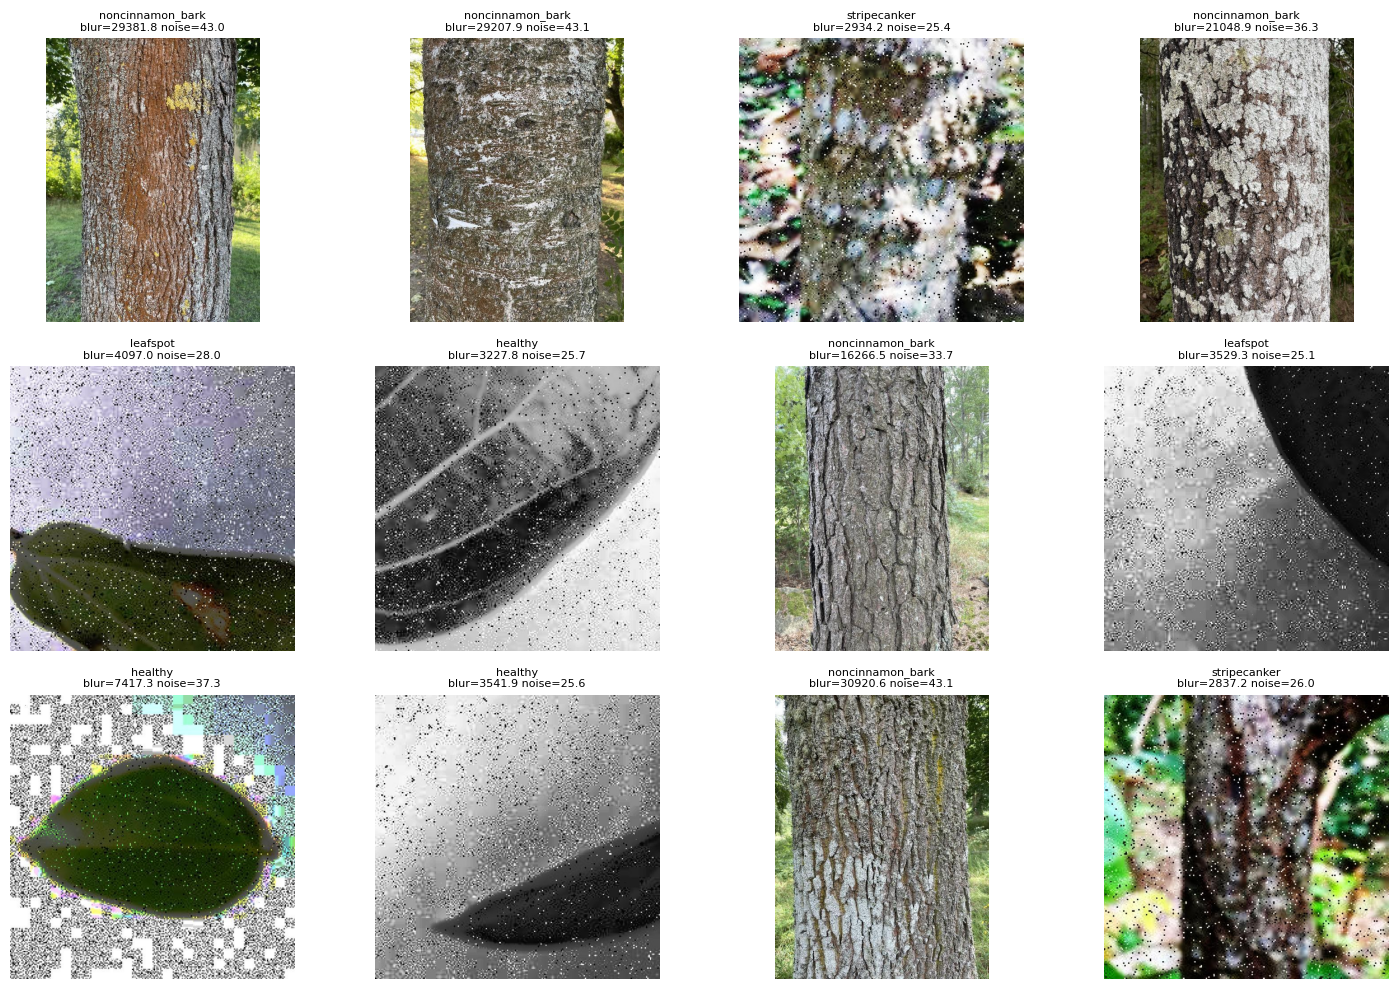


👀 Cek dulu gambar di atas. Kalau memang rusak, jalankan cell berikutnya untuk menghapus.


In [5]:
import cv2
import numpy as np
import os
import random
import pandas as pd
import matplotlib.pyplot as plt

def compute_quality_scores(image_path):
    img = cv2.imread(image_path)
    if img is None:
        return None, None
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    blur_score = cv2.Laplacian(gray, cv2.CV_64F).var()
    denoised = cv2.medianBlur(gray, 5)
    noise_score = np.std(gray.astype(np.float32) - denoised.astype(np.float32))
    return blur_score, noise_score

def scan_dataset_quality(root_dir, blur_threshold=15, noise_threshold=25):
    flagged = []
    for cls in sorted(os.listdir(root_dir)):
        cls_path = os.path.join(root_dir, cls)
        if not os.path.isdir(cls_path):
            continue
        for fname in os.listdir(cls_path):
            fpath = os.path.join(cls_path, fname)
            blur_score, noise_score = compute_quality_scores(fpath)
            if blur_score is None:
                continue
            if blur_score < blur_threshold or noise_score > noise_threshold:
                flagged.append({'path': fpath, 'class': cls,
                                 'blur_score': blur_score, 'noise_score': noise_score})
    return flagged

train_dir_check = '/kaggle/working/dataset_split_clean/train'
flagged_images = scan_dataset_quality(train_dir_check)

total = sum(len(os.listdir(os.path.join(train_dir_check, c))) for c in os.listdir(train_dir_check))
print(f"Total gambar training: {total}")
print(f"Gambar ditandai rusak berat (blur/noise ekstrem): {len(flagged_images)}")

if flagged_images:
    df_flagged = pd.DataFrame(flagged_images)
    print(df_flagged.groupby('class').size())

    sample_check = random.sample(flagged_images, min(12, len(flagged_images)))
    plt.figure(figsize=(15, 10))
    for i, item in enumerate(sample_check):
        img = cv2.cvtColor(cv2.imread(item['path']), cv2.COLOR_BGR2RGB)
        plt.subplot(3, 4, i + 1)
        plt.imshow(img)
        plt.title(f"{item['class']}\nblur={item['blur_score']:.1f} noise={item['noise_score']:.1f}", fontsize=8)
        plt.axis('off')
    plt.tight_layout()
    plt.show()
    print("\n👀 Cek dulu gambar di atas. Kalau memang rusak, jalankan cell berikutnya untuk menghapus.")
else:
    print("Tidak ada gambar yang ditandai rusak.")

In [6]:
# Jangan menghapus file secara otomatis.
# flagged_images hanya digunakan untuk pemeriksaan kualitas.

print(f"Total gambar yang terdeteksi oleh quality filter: {len(flagged_images)}")

if flagged_images:
    print("\nContoh gambar yang terdeteksi:")
    
    for item in flagged_images[:20]:
        print(
            f"Kelas: {item['class']} | "
            f"Blur: {item['blur_score']:.2f} | "
            f"Noise: {item['noise_score']:.2f} | "
            f"File: {os.path.basename(item['path'])}"
        )

print("\n⚠️ Tidak ada file yang dihapus otomatis.")
print("Lakukan pemeriksaan visual terlebih dahulu sebelum menghapus data.")

Total gambar yang terdeteksi oleh quality filter: 737

Contoh gambar yang terdeteksi:
Kelas: healthy | Blur: 4433.16 | Noise: 29.31 | File: 20220816_113004_jpg.rf.17d980278aeee08c547bff58eb87608e.jpg
Kelas: healthy | Blur: 3485.83 | Noise: 26.40 | File: 20220816_112913_jpg.rf.06bc258b682c1ba07cae9a0d646ba134.jpg
Kelas: healthy | Blur: 6935.02 | Noise: 35.28 | File: 20220816_112901_jpg.rf.dfffd67c69ebce6ac534021fa1ad895e.jpg
Kelas: healthy | Blur: 3656.26 | Noise: 25.82 | File: 20220816_112957_jpg.rf.5a5f47568c34941ee3faf13a8e1a1d53.jpg
Kelas: healthy | Blur: 2981.13 | Noise: 25.18 | File: IMG_20220816_131142_jpg.rf.6e8230bd1d92f32af65b81f8ab05c0b2.jpg
Kelas: healthy | Blur: 3044.80 | Noise: 25.16 | File: IMG_20220815_183138_1_jpg.rf.e5fc54ee3a8d757ad851b3c71e62f685.jpg
Kelas: healthy | Blur: 14.80 | Noise: 1.29 | File: 20220816_113138_jpg.rf.7d872f3698a9719bc79f4947cf638ef2.jpg
Kelas: healthy | Blur: 3882.13 | Noise: 27.92 | File: 20220823_110518_jpg.rf.1473ade6160c1b1f7a6d4ef9ce8ec973

In [7]:
import numpy as np
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.resnet50 import preprocess_input

train_dir = '/kaggle/working/dataset_split_clean/train'
val_dir = '/kaggle/working/dataset_split_clean/val'
test_dir = '/kaggle/working/dataset_split_clean/test'

train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=20,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

val_test_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

batch_size = 32

train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(224, 224),
    batch_size=batch_size,
    class_mode='categorical',
    shuffle=True
)

val_generator = val_test_datagen.flow_from_directory(
    val_dir,
    target_size=(224, 224),
    batch_size=batch_size,
    class_mode='categorical',
    shuffle=False
)

test_generator = val_test_datagen.flow_from_directory(
    test_dir,
    target_size=(224, 224),
    batch_size=batch_size,
    class_mode='categorical',
    shuffle=False
)

train_classes = train_generator.classes

class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_classes),
    y=train_classes
)

class_weight_dict = dict(enumerate(class_weights))

print("Class weights:")
print(class_weight_dict)

2026-10-24 18:06:50.094078: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1792865210.346550      22 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1792865210.413222      22 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1792865211.040676      22 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1792865211.040715      22 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1792865211.040718      22 computation_placer.cc:177] computation placer alr

Found 5136 images belonging to 6 classes.
Found 643 images belonging to 6 classes.
Found 631 images belonging to 6 classes.
Class weights:
{0: np.float64(0.7608888888888888), 1: np.float64(0.9661399548532731), 2: np.float64(1.6557059961315281), 3: np.float64(2.145363408521303), 4: np.float64(0.7475982532751092), 5: np.float64(0.8045112781954887)}



TRAINING MODEL: ResNet50
Found 5136 images belonging to 6 classes.
Found 643 images belonging to 6 classes.


I0000 00:00:1792865235.334161      22 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792865235.340279      22 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step

ResNet50 - PHASE 1


Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.


Epoch 1/10


...

161/161 ━━━━━━━━━━━━━━━━━━━━ 0s 434ms/step - accuracy: 0.7268 - loss: 3.6001

2026-10-24 19:08:01.808638: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-24 19:08:01.944479: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


161/161 ━━━━━━━━━━━━━━━━━━━━ 100s 533ms/step - accuracy: 0.7273 - loss: 3.5948 - val_accuracy: 0.8351 - val_loss: 1.8369
Epoch 2/10
161/161 ━━━━━━━━━━━━━━━━━━━━ 64s 398ms/step - accuracy: 0.8606 - loss: 1.4624 - val_accuracy: 0.8818 - val_loss: 1.0082
Epoch 3/10
161/161 ━━━━━━━━━━━━━━━━━━━━ 65s 406ms/step - accuracy: 0.8822 - loss: 0.8511 - val_accuracy: 0.8491 - val_loss: 0.7598
Epoch 4/10
161/161 ━━━━━━━━━━━━━━━━━━━━ 64s 395ms/step - accuracy: 0.8802 - loss: 0.6266 - val_accuracy: 0.8771 - val_loss: 0.6001
Epoch 5/10
161/161 ━━━━━━━━━━━━━━━━━━━━ 64s 395ms/step - accuracy: 0.8883 - loss: 0.5160 - val_accuracy: 0.8616 - val_loss: 0.5333
Epoch 6/10
161/161 ━━━━━━━━━━━━━━━━━━━━ 64s 396ms/step - accuracy: 0.8820 - loss: 0.4815 - val_accuracy: 0.8305 - val_loss: 0.7249
Epoch 7/10
161/161 ━━━━━━━━━━━━━━━━━━━━ 64s 396ms/step - accuracy: 0.8817 - loss: 0.4552 - val_accuracy: 0.8507 - val_loss: 0.5834
Epoch 8/10
161/161 ━━━━━━━━━━━━━━━━━━━━ 65s 405ms/step - accuracy: 0.8935 - loss: 0.4487 - va

Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.


Epoch 1/10
161/161 ━━━━━━━━━━━━━━━━━━━━ 130s 638ms/step - accuracy: 0.6506 - loss: 2.9099 - val_accuracy: 0.8725 - val_loss: 1.2140
Epoch 2/10
161/161 ━━━━━━━━━━━━━━━━━━━━ 67s 417ms/step - accuracy: 0.8635 - loss: 1.0580 - val_accuracy: 0.8709 - val_loss: 0.8281
Epoch 3/10
161/161 ━━━━━━━━━━━━━━━━━━━━ 66s 412ms/step - accuracy: 0.8829 - loss: 0.7132 - val_accuracy: 0.8880 - val_loss: 0.6318
Epoch 4/10
161/161 ━━━━━━━━━━━━━━━━━━━━ 68s 420ms/step - accuracy: 0.8659 - loss: 0.5816 - val_accuracy: 0.8880 - val_loss: 0.5453
Epoch 5/10
161/161 ━━━━━━━━━━━━━━━━━━━━ 67s 415ms/step - accuracy: 0.8752 - loss: 0.4949 - val_accuracy: 0.8709 - val_loss: 0.5122
Epoch 6/10
161/161 ━━━━━━━━━━━━━━━━━━━━ 66s 412ms/step - accuracy: 0.8876 - loss: 0.4380 - val_accuracy: 0.8802 - val_loss: 0.5047
Epoch 7/10
161/161 ━━━━━━━━━━━━━━━━━━━━ 67s 414ms/step - accuracy: 0.8930 - loss: 0.4051 - val_accuracy: 0.8927 - val_loss: 0.4362
Epoch 8/10
161/161 ━━━━━━━━━━━━━━━━━━━━ 67s 413ms/step - accuracy: 0.8879 - loss: 

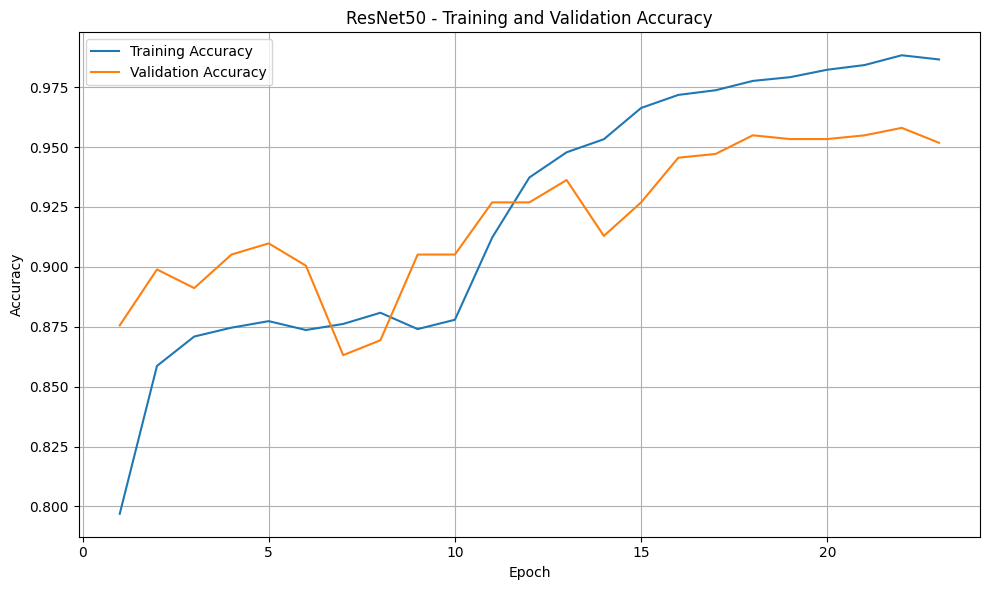

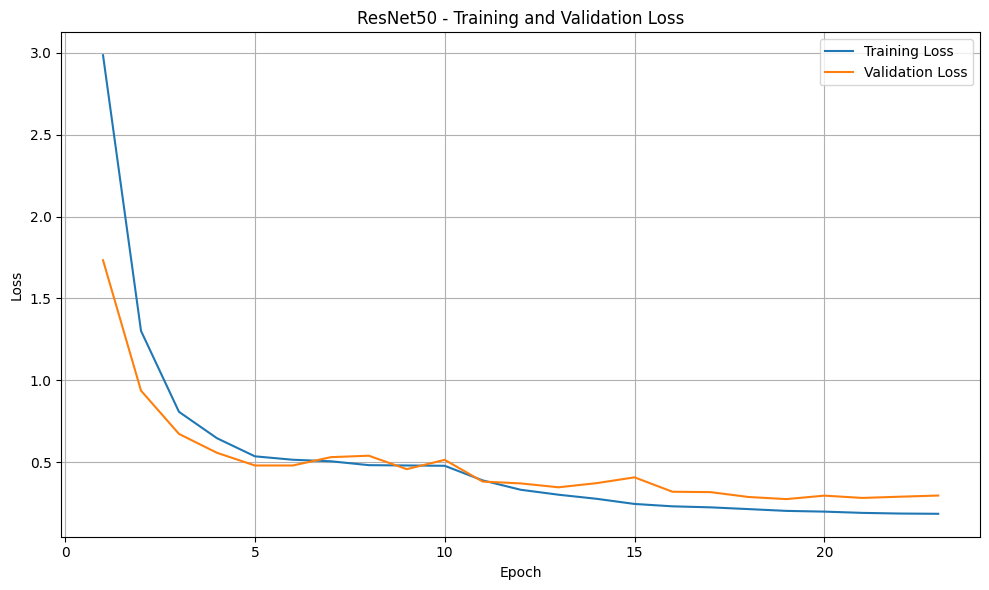

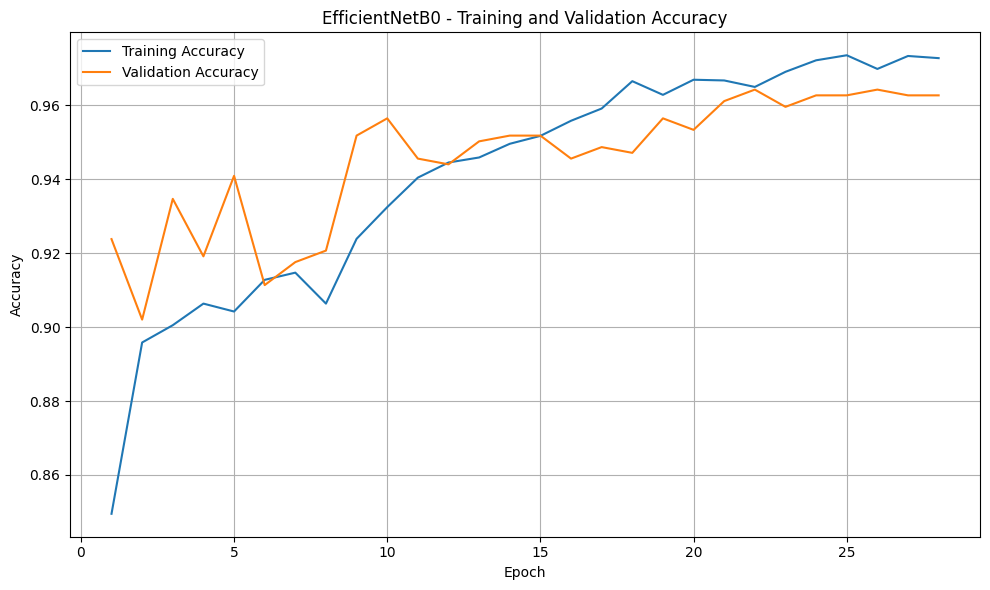

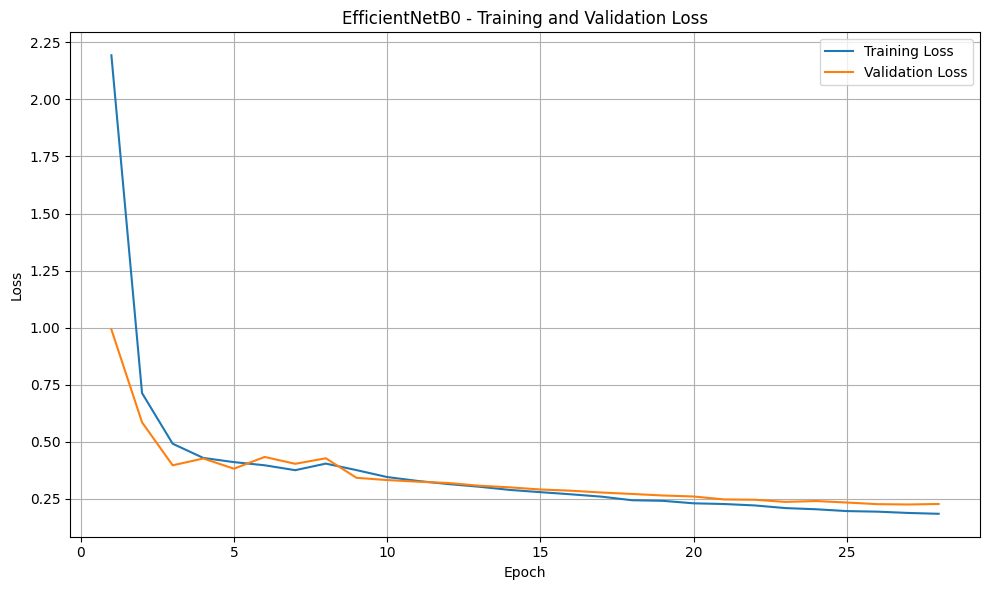

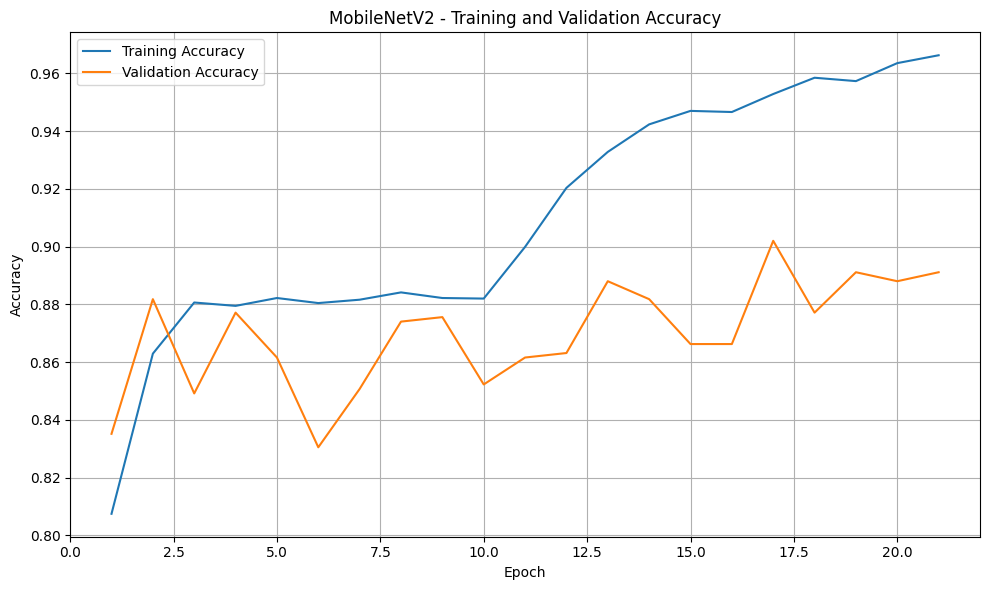

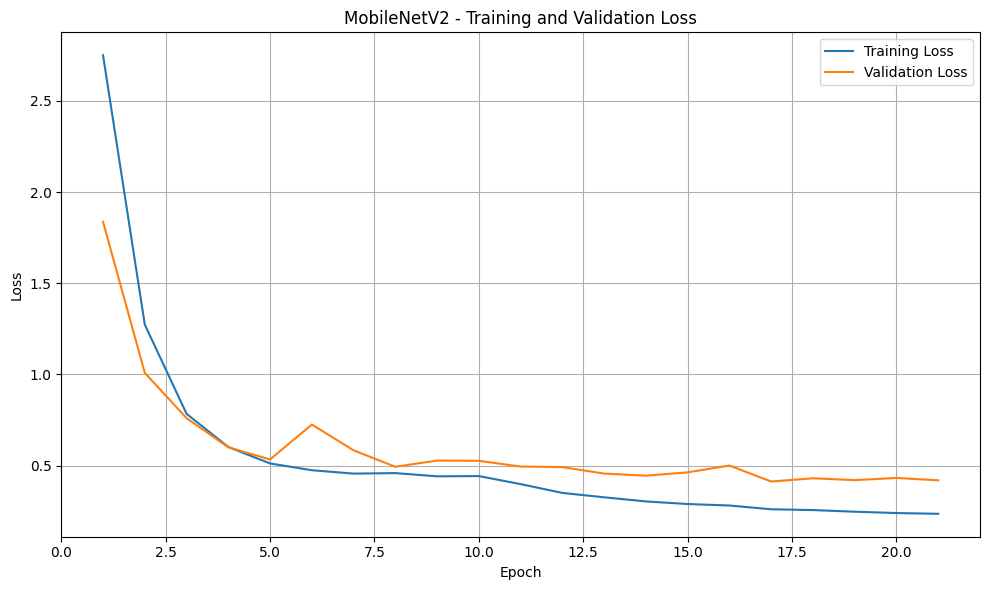

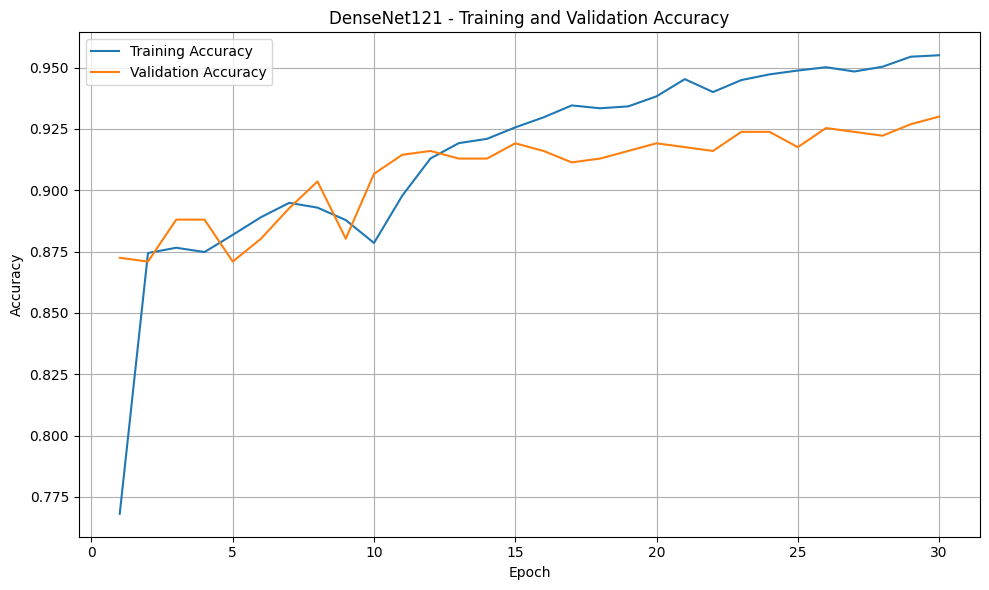

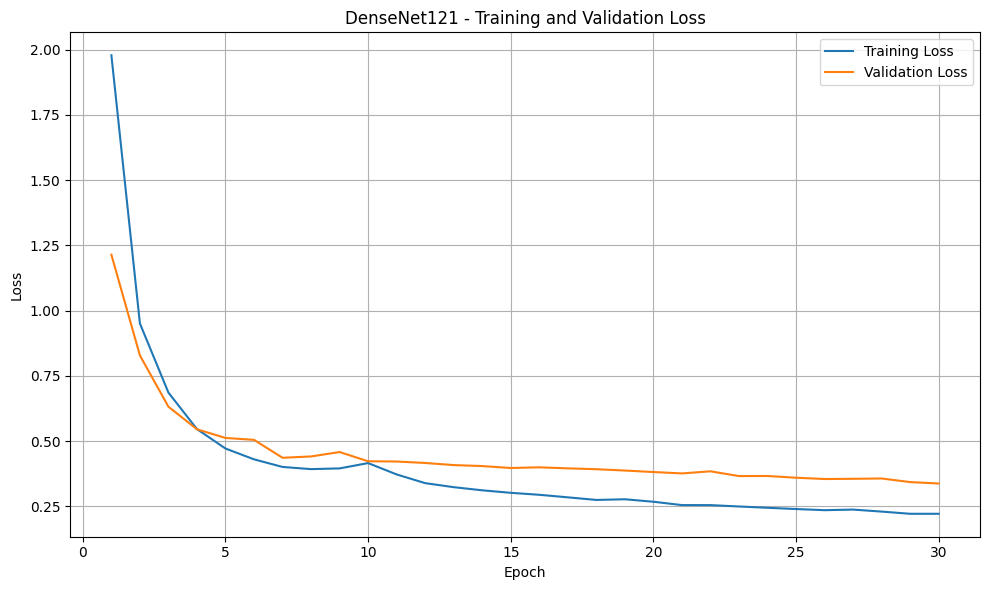

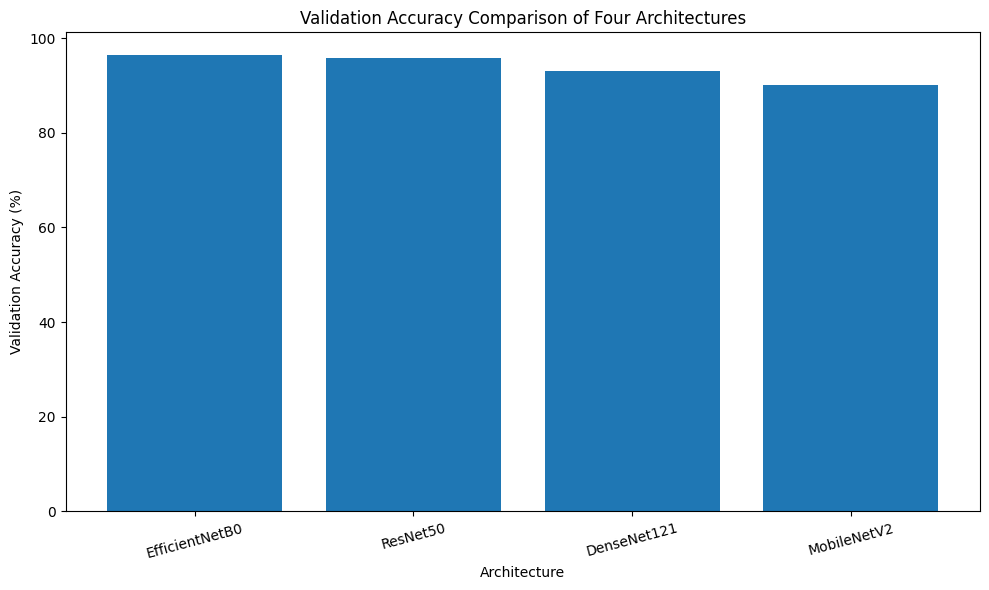


File hasil training:
Results : /kaggle/working/model_comparison_results.json
History : /kaggle/working/model_comparison_histories.json
Plots   : /kaggle/working/model_comparison_plots
Best Model : /kaggle/working/best_EfficientNetB0_comparison.keras


In [8]:
# ============================================================
# PERBANDINGAN 4 ARSITEKTUR
# ============================================================

import os
import json
import gc
import shutil
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras.applications import (
    ResNet50,
    EfficientNetB0,
    MobileNetV2,
    DenseNet121
)

from tensorflow.keras.applications.resnet50 import (
    preprocess_input as resnet_preprocess
)

from tensorflow.keras.applications.efficientnet import (
    preprocess_input as efficientnet_preprocess
)

from tensorflow.keras.applications.mobilenet_v2 import (
    preprocess_input as mobilenet_preprocess
)

from tensorflow.keras.applications.densenet import (
    preprocess_input as densenet_preprocess
)

from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Dense,
    GlobalAveragePooling2D,
    Dropout
)

from tensorflow.keras.optimizers import Adam

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint,
    BackupAndRestore
)

from tensorflow.keras import regularizers
from tensorflow.keras.preprocessing.image import ImageDataGenerator

from sklearn.utils.class_weight import compute_class_weight


# ============================================================
# PATH
# ============================================================

train_dir = '/kaggle/working/dataset_split_clean/train'
val_dir = '/kaggle/working/dataset_split_clean/val'
test_dir = '/kaggle/working/dataset_split_clean/test'

RESULTS_FILE = '/kaggle/working/model_comparison_results.json'
HISTORY_FILE = '/kaggle/working/model_comparison_histories.json'

BACKUP_DIR = '/kaggle/working/model_backups'
PLOT_DIR = '/kaggle/working/model_comparison_plots'

os.makedirs(BACKUP_DIR, exist_ok=True)
os.makedirs(PLOT_DIR, exist_ok=True)


# ============================================================
# MODEL CONFIGURATION
# ============================================================

MODEL_CONFIGS = {

    'ResNet50': {
        'base_class': ResNet50,
        'preprocess': resnet_preprocess
    },

    'EfficientNetB0': {
        'base_class': EfficientNetB0,
        'preprocess': efficientnet_preprocess
    },

    'MobileNetV2': {
        'base_class': MobileNetV2,
        'preprocess': mobilenet_preprocess
    },

    'DenseNet121': {
        'base_class': DenseNet121,
        'preprocess': densenet_preprocess
    }
}


# ============================================================
# PARAMETER
# ============================================================

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

PHASE1_EPOCHS = 10
PHASE2_EPOCHS = 20

UNFREEZE_N = 20

LEARNING_RATE_PHASE1 = 0.001
LEARNING_RATE_PHASE2 = 1e-5

NUM_CLASSES = 6


# ============================================================
# BUILD MODEL
# ============================================================

def build_comparison_model(base_class):

    base = base_class(
        weights='imagenet',
        include_top=False,
        input_shape=(224, 224, 3)
    )

    # Phase 1: backbone dibekukan
    base.trainable = False

    x = base.output

    x = GlobalAveragePooling2D()(x)

    x = Dense(
        512,
        activation='relu',
        kernel_regularizer=regularizers.l2(0.005)
    )(x)

    x = Dropout(0.6)(x)

    output = Dense(
        NUM_CLASSES,
        activation='softmax'
    )(x)

    model = Model(
        inputs=base.input,
        outputs=output
    )

    model.compile(
        optimizer=Adam(
            learning_rate=LEARNING_RATE_PHASE1
        ),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    return model, base


# ============================================================
# GENERATOR
# ============================================================

def make_comparison_generators(preprocess_fn):

    train_datagen = ImageDataGenerator(
        preprocessing_function=preprocess_fn,
        rotation_range=20,
        zoom_range=0.2,
        horizontal_flip=True,
        fill_mode='nearest'
    )

    eval_datagen = ImageDataGenerator(
        preprocessing_function=preprocess_fn
    )

    train_gen = train_datagen.flow_from_directory(
        train_dir,
        target_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        class_mode='categorical',
        shuffle=True,
        seed=42
    )

    val_gen = eval_datagen.flow_from_directory(
        val_dir,
        target_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        class_mode='categorical',
        shuffle=False
    )

    return train_gen, val_gen


# ============================================================
# RESET HASIL COMPARISON LAMA
# ============================================================
# Hasil comparison lama dihapus agar 4 model benar-benar
# dievaluasi berdasarkan training baru.
#
# BackupAndRestore TIDAK dihapus, sehingga jika runtime
# terputus, training dapat mencoba melanjutkan dari backup.

if os.path.exists(RESULTS_FILE):
    os.remove(RESULTS_FILE)

if os.path.exists(HISTORY_FILE):
    os.remove(HISTORY_FILE)


# ============================================================
# HASIL
# ============================================================

comparison_results = {}
comparison_histories = {}


# ============================================================
# TRAINING 4 ARSITEKTUR
# ============================================================

for model_name, config in MODEL_CONFIGS.items():

    print("\n" + "=" * 70)
    print(f"TRAINING MODEL: {model_name}")
    print("=" * 70)


    # --------------------------------------------------------
    # CHECKPOINT
    # --------------------------------------------------------

    checkpoint_path = (
        f'/kaggle/working/'
        f'best_{model_name}_comparison.keras'
    )


    # --------------------------------------------------------
    # GENERATOR
    # --------------------------------------------------------

    train_gen, val_gen = make_comparison_generators(
        config['preprocess']
    )


    # --------------------------------------------------------
    # CLASS WEIGHT
    # --------------------------------------------------------

    class_weights = compute_class_weight(
        class_weight='balanced',
        classes=np.unique(train_gen.classes),
        y=train_gen.classes
    )

    class_weight_dict = dict(
        enumerate(class_weights)
    )


    # --------------------------------------------------------
    # BUILD MODEL
    # --------------------------------------------------------

    model, base = build_comparison_model(
        config['base_class']
    )


    # ========================================================
    # PHASE 1
    # ========================================================

    print(f"\n{model_name} - PHASE 1")

    phase1_backup = os.path.join(
        BACKUP_DIR,
        f'{model_name}_phase1'
    )

    history_phase1 = model.fit(
        train_gen,
        epochs=PHASE1_EPOCHS,
        validation_data=val_gen,
        class_weight=class_weight_dict,

        callbacks=[
            EarlyStopping(
                monitor='val_loss',
                patience=3,
                restore_best_weights=True,
                verbose=1
            ),

            BackupAndRestore(
                backup_dir=phase1_backup,
                delete_checkpoint=False
            )
        ],

        verbose=1
    )


    # ========================================================
    # PHASE 2 - FINE TUNING
    # ========================================================

    print(f"\n{model_name} - PHASE 2 FINE-TUNING")

    base.trainable = True


    # Bekukan semua layer kecuali N layer terakhir
    for layer in base.layers[:-UNFREEZE_N]:
        layer.trainable = False


    # Aktifkan N layer terakhir
    for layer in base.layers[-UNFREEZE_N:]:
        layer.trainable = True


    # --------------------------------------------------------
    # BATCH NORMALIZATION TETAP BEKU
    # --------------------------------------------------------

    for layer in base.layers[-UNFREEZE_N:]:

        if isinstance(
            layer,
            tf.keras.layers.BatchNormalization
        ):
            layer.trainable = False


    # --------------------------------------------------------
    # COMPILE ULANG
    # --------------------------------------------------------

    model.compile(
        optimizer=Adam(
            learning_rate=LEARNING_RATE_PHASE2
        ),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )


    phase2_backup = os.path.join(
        BACKUP_DIR,
        f'{model_name}_phase2'
    )


    # ========================================================
    # PHASE 2 TRAINING
    # ========================================================

    history_phase2 = model.fit(
        train_gen,
        epochs=PHASE2_EPOCHS,
        validation_data=val_gen,
        class_weight=class_weight_dict,

        callbacks=[
            EarlyStopping(
                monitor='val_loss',
                patience=4,
                restore_best_weights=True,
                verbose=1
            ),

            ReduceLROnPlateau(
                monitor='val_loss',
                factor=0.5,
                patience=2,
                min_lr=1e-7,
                verbose=1
            ),

            ModelCheckpoint(
                checkpoint_path,
                monitor='val_accuracy',
                save_best_only=True,
                verbose=1
            ),

            BackupAndRestore(
                backup_dir=phase2_backup,
                delete_checkpoint=False
            )
        ],

        verbose=1
    )


    # ========================================================
    # GABUNGKAN HISTORY PHASE 1 + PHASE 2
    # ========================================================

    history = {}

    for key in history_phase1.history.keys():

        history[key] = [
            float(x)
            for x in history_phase1.history[key]
        ]


    for key in history_phase2.history.keys():

        if key not in history:
            history[key] = []

        history[key].extend([
            float(x)
            for x in history_phase2.history[key]
        ])


    comparison_histories[model_name] = history


    # ========================================================
    # SIMPAN HISTORY
    # ========================================================

    with open(
        HISTORY_FILE,
        'w'
    ) as f:

        json.dump(
            comparison_histories,
            f,
            indent=2
        )


    # ========================================================
    # LOAD BEST MODEL
    # ========================================================

    if os.path.exists(checkpoint_path):

        best_model = tf.keras.models.load_model(
            checkpoint_path
        )

    else:

        best_model = model


    # ========================================================
    # VALIDATION EVALUATION
    # ========================================================

    val_loss, val_acc = best_model.evaluate(
        val_gen,
        verbose=0
    )


    print(
        f"\n{model_name} - "
        f"Validation Accuracy: "
        f"{val_acc * 100:.2f}%"
    )


    # ========================================================
    # SIMPAN HASIL COMPARISON
    # ========================================================

    comparison_results[model_name] = {

        'validation_accuracy': float(
            val_acc
        ),

        'validation_loss': float(
            val_loss
        ),

        'checkpoint': checkpoint_path,

        'total_params': int(
            best_model.count_params()
        )
    }


    with open(
        RESULTS_FILE,
        'w'
    ) as f:

        json.dump(
            comparison_results,
            f,
            indent=2
        )


    print(
        f"✅ Hasil {model_name} tersimpan."
    )


    # ========================================================
    # CLEAN MEMORY
    # ========================================================

    del best_model
    del model
    del base
    del train_gen
    del val_gen

    tf.keras.backend.clear_session()
    gc.collect()


# ============================================================
# HASIL AKHIR PERBANDINGAN
# ============================================================

df_validation = (
    pd.DataFrame(comparison_results)
    .T
    .sort_values(
        'validation_accuracy',
        ascending=False
    )
)


print("\n" + "=" * 70)
print("HASIL PERBANDINGAN 4 ARSITEKTUR")
print("=" * 70)

print(df_validation)


# ============================================================
# MODEL TERBAIK
# ============================================================

best_model_name = df_validation.index[0]

best_model_path = comparison_results[
    best_model_name
]['checkpoint']

best_validation_accuracy = comparison_results[
    best_model_name
]['validation_accuracy']


print("\n" + "=" * 70)

print(
    f"MODEL TERBAIK : {best_model_name}"
)

print(
    f"VALIDATION ACCURACY : "
    f"{best_validation_accuracy * 100:.2f}%"
)

print(
    f"CHECKPOINT : {best_model_path}"
)

print("=" * 70)


# ============================================================
# GRAFIK TRAINING
# ============================================================

for model_name, history in comparison_histories.items():

    epochs = range(
        1,
        len(history['accuracy']) + 1
    )


    # ========================================================
    # ACCURACY
    # ========================================================

    plt.figure(figsize=(10, 6))

    plt.plot(
        epochs,
        history['accuracy'],
        label='Training Accuracy'
    )

    plt.plot(
        epochs,
        history['val_accuracy'],
        label='Validation Accuracy'
    )

    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')

    plt.title(
        f'{model_name} - Training and Validation Accuracy'
    )

    plt.legend()
    plt.grid(True)

    plt.tight_layout()

    accuracy_path = os.path.join(
        PLOT_DIR,
        f'{model_name}_accuracy.png'
    )

    plt.savefig(
        accuracy_path,
        dpi=300,
        bbox_inches='tight'
    )

    plt.show()

    plt.close()


    # ========================================================
    # LOSS
    # ========================================================

    plt.figure(figsize=(10, 6))

    plt.plot(
        epochs,
        history['loss'],
        label='Training Loss'
    )

    plt.plot(
        epochs,
        history['val_loss'],
        label='Validation Loss'
    )

    plt.xlabel('Epoch')
    plt.ylabel('Loss')

    plt.title(
        f'{model_name} - Training and Validation Loss'
    )

    plt.legend()
    plt.grid(True)

    plt.tight_layout()

    loss_path = os.path.join(
        PLOT_DIR,
        f'{model_name}_loss.png'
    )

    plt.savefig(
        loss_path,
        dpi=300,
        bbox_inches='tight'
    )

    plt.show()

    plt.close()


# ============================================================
# GRAFIK PERBANDINGAN VALIDATION ACCURACY
# ============================================================

plt.figure(figsize=(10, 6))

plt.bar(
    df_validation.index,
    df_validation['validation_accuracy'] * 100
)

plt.xlabel('Architecture')
plt.ylabel('Validation Accuracy (%)')

plt.title(
    'Validation Accuracy Comparison of Four Architectures'
)

plt.xticks(rotation=15)

plt.tight_layout()

comparison_plot_path = os.path.join(
    PLOT_DIR,
    'architecture_validation_accuracy_comparison.png'
)

plt.savefig(
    comparison_plot_path,
    dpi=300,
    bbox_inches='tight'
)

plt.show()

plt.close()


# ============================================================
# INFORMASI OUTPUT
# ============================================================

print("\nFile hasil training:")

print(
    f"Results : {RESULTS_FILE}"
)

print(
    f"History : {HISTORY_FILE}"
)

print(
    f"Plots   : {PLOT_DIR}"
)

print(
    f"Best Model : {best_model_path}"
)

In [9]:
# ============================================================
# MEMILIH MODEL TERBAIK BERDASARKAN VALIDATION ACCURACY
# ============================================================

import json
import pandas as pd

RESULTS_FILE = '/kaggle/working/model_comparison_results.json'

with open(RESULTS_FILE, 'r') as f:
    comparison_results = json.load(f)

df_validation = (
    pd.DataFrame(comparison_results)
    .T
    .sort_values(
        'validation_accuracy',
        ascending=False
    )
)

print("=" * 70)
print("HASIL VALIDASI MODEL")
print("=" * 70)

print(
    df_validation[
        [
            'validation_accuracy',
            'validation_loss',
            'total_params',
            'checkpoint'
        ]
    ]
)

best_model_name = df_validation.index[0]

best_model_path = comparison_results[
    best_model_name
]['checkpoint']

print("\n" + "=" * 70)
print("MODEL TERBAIK")
print("=" * 70)

print(f"Model               : {best_model_name}")

print(
    f"Validation Accuracy : "
    f"{comparison_results[best_model_name]['validation_accuracy'] * 100:.2f}%"
)

print(
    f"Validation Loss     : "
    f"{comparison_results[best_model_name]['validation_loss']:.4f}"
)

print(
    f"Checkpoint          : "
    f"{best_model_path}"
)

HASIL VALIDASI MODEL
               validation_accuracy validation_loss total_params  \
EfficientNetB0             0.96423        0.246108      4708521   
ResNet50                  0.958009        0.288353     24639878   
DenseNet121               0.930016        0.337554      7565382   
MobileNetV2               0.902022         0.41225      2916934   

                                                       checkpoint  
EfficientNetB0  /kaggle/working/best_EfficientNetB0_comparison...  
ResNet50           /kaggle/working/best_ResNet50_comparison.keras  
DenseNet121     /kaggle/working/best_DenseNet121_comparison.keras  
MobileNetV2     /kaggle/working/best_MobileNetV2_comparison.keras  

MODEL TERBAIK
Model               : EfficientNetB0
Validation Accuracy : 96.42%
Validation Loss     : 0.2461
Checkpoint          : /kaggle/working/best_EfficientNetB0_comparison.keras


In [ ]:
# ============================================================
# FINAL EXTERNAL TEST
# Model terbaik dipilih otomatis berdasarkan validation accuracy
# ============================================================

import os
import json
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)


# ============================================================
# PATH & DATASET DISCOVERY / AUTO-DOWNLOAD
# ============================================================

CSV_PATH = None

# 1. Cari di /kaggle/input (diutamakan folder 'test')
if os.path.exists('/kaggle/input'):
    for root, dirs, files in os.walk('/kaggle/input'):
        if '_classes.csv' in files and os.path.basename(root).lower() == 'test':
            CSV_PATH = os.path.join(root, '_classes.csv')
            break
    if CSV_PATH is None:
        for root, dirs, files in os.walk('/kaggle/input'):
            if '_classes.csv' in files:
                CSV_PATH = os.path.join(root, '_classes.csv')
                break

# 2. Cari di /kaggle/working jika belum ditemukan di /kaggle/input
if CSV_PATH is None and os.path.exists('/kaggle/working'):
    for root, dirs, files in os.walk('/kaggle/working'):
        if '_classes.csv' in files and os.path.basename(root).lower() == 'test':
            CSV_PATH = os.path.join(root, '_classes.csv')
            break
    if CSV_PATH is None:
        for root, dirs, files in os.walk('/kaggle/working'):
            if '_classes.csv' in files:
                CSV_PATH = os.path.join(root, '_classes.csv')
                break

# 3. Jika belum ditemukan di mana pun, unduh otomatis (Roboflow API atau Fallback Direct ZIP)
if CSV_PATH is None:
    print("Dataset external test tidak ditemukan di /kaggle/input maupun /kaggle/working.")
    print("Mengunduh dataset external secara otomatis...")

    # Metode A: Roboflow API
    try:
        from roboflow import Roboflow
        rf = Roboflow(api_key="3wZ1HEwzSwHhFGO7FLwv")
        ext_proj = rf.workspace("kalhara-vithanage").project("cinnamon-multiple-diseases")
        ext_ds = ext_proj.version(1).download("multiclass")
    except Exception as e_rf:
        print(f"Download via Roboflow API dilewati ({e_rf}).")

    # Metode B: Fallback direct ZIP download dari endpoint Roboflow
    ext_dir_working = '/kaggle/working/cinnamon-multiple-diseases-1'
    has_csv_working = os.path.exists(ext_dir_working) and any(
        '_classes.csv' in f for _, _, f in os.walk(ext_dir_working)
    )
    if not has_csv_working:
        try:
            import urllib.request, zipfile, io, ssl
            print("Mencoba download langsung file zip dataset external...")
            zip_url = "https://app.roboflow.com/ds/mEOKFzSdwv?key=mThMXWIM7l"
            os.makedirs(ext_dir_working, exist_ok=True)
            ctx = ssl._create_unverified_context()
            req = urllib.request.Request(zip_url, headers={"User-Agent": "Mozilla/5.0"})
            with urllib.request.urlopen(req, context=ctx, timeout=60) as resp:
                z = zipfile.ZipFile(io.BytesIO(resp.read()))
                z.extractall(ext_dir_working)
            print("✅ Download dan ekstraksi dataset external berhasil!")
        except Exception as e_zip:
            print(f"Direct zip download gagal: {e_zip}")

    # Cari ulang di /kaggle/working
    for root, dirs, files in os.walk('/kaggle/working'):
        if '_classes.csv' in files and os.path.basename(root).lower() == 'test':
            CSV_PATH = os.path.join(root, '_classes.csv')
            break
    if CSV_PATH is None:
        for root, dirs, files in os.walk('/kaggle/working'):
            if '_classes.csv' in files:
                CSV_PATH = os.path.join(root, '_classes.csv')
                break

if CSV_PATH is None or not os.path.exists(CSV_PATH):
    raise FileNotFoundError(
        "Gagal menemukan atau mengunduh dataset external test (_classes.csv)."
    )

EXTERNAL_TEST_DIR = os.path.dirname(CSV_PATH)
print("✅ CSV External Test ditemukan:", CSV_PATH)
print("✅ Direktori External Test     :", EXTERNAL_TEST_DIR)

RESULTS_FILE = (
    "/kaggle/working/model_comparison_results.json"
)

OUTPUT_DIR = (
    "/kaggle/working/visualisasi_hasil"
)

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)

# ============================================================
# LOAD HASIL COMPARISON
# ============================================================

if not os.path.exists(RESULTS_FILE):

    raise FileNotFoundError(
        f"File hasil comparison tidak ditemukan:\n"
        f"{RESULTS_FILE}"
    )

with open(
    RESULTS_FILE,
    "r"
) as f:

    comparison_results = json.load(f)


# ============================================================
# PILIH MODEL TERBAIK OTOMATIS
# ============================================================

best_model_name = max(
    comparison_results,
    key=lambda x:
    comparison_results[x]["validation_accuracy"]
)

checkpoint_path = comparison_results[
    best_model_name
]["checkpoint"]

best_validation_accuracy = (
    comparison_results[
        best_model_name
    ]["validation_accuracy"]
)


print("=" * 70)
print("MODEL TERBAIK UNTUK EXTERNAL TEST")
print("=" * 70)

print(
    f"Best Model            : {best_model_name}"
)

print(
    f"Validation Accuracy   : "
    f"{best_validation_accuracy * 100:.2f}%"
)

print(
    f"Checkpoint            : {checkpoint_path}"
)


if not os.path.exists(checkpoint_path):

    raise FileNotFoundError(
        f"Checkpoint tidak ditemukan:\n"
        f"{checkpoint_path}"
    )


# ============================================================
# CLASS MAPPING
# ============================================================

external_to_model = {

    "healthy_cinnamon":
        "healthy",

    "leaf_spot_disease":
        "leafspot",

    "rough_bark":
        "roughbark",

    "stripe_canker":
        "stripecanker"
}


model_classes = [

    "healthy",
    "leafspot",
    "noncinnamon_bark",
    "noncinnamon_leaves",
    "roughbark",
    "stripecanker"
]


model_class_to_idx = {

    name: idx

    for idx, name in enumerate(
        model_classes
    )
}


external_class_names = [

    "healthy",
    "leafspot",
    "roughbark",
    "stripecanker"
]


external_model_indices = [

    model_class_to_idx["healthy"],
    model_class_to_idx["leafspot"],
    model_class_to_idx["roughbark"],
    model_class_to_idx["stripecanker"]
]


label_cols = [

    "healthy_cinnamon",
    "leaf_spot_disease",
    "rough_bark",
    "stripe_canker"
]


# ============================================================
# LOAD CSV
# ============================================================

if not os.path.exists(CSV_PATH):

    raise FileNotFoundError(
        f"_classes.csv tidak ditemukan:\n"
        f"{CSV_PATH}"
    )

df_ext = pd.read_csv(
    CSV_PATH
)

df_ext.columns = (
    df_ext.columns
    .astype(str)
    .str.strip()
)


print(
    f"\nJumlah data dalam CSV : {len(df_ext)}"
)

print(
    "Kolom CSV:",
    list(df_ext.columns)
)


# ============================================================
# VALIDASI KOLOM
# ============================================================

required_columns = [
    "filename"
] + label_cols

missing_columns = [

    col

    for col in required_columns

    if col not in df_ext.columns
]

if missing_columns:

    raise ValueError(
        "Kolom berikut tidak ditemukan:\n"
        + str(missing_columns)
    )


# ============================================================
# GROUND TRUTH
# ============================================================

y_true = []

image_paths = []

used_filenames = []

skipped_rows = 0


for _, row in df_ext.iterrows():

    filename = str(
        row["filename"]
    ).strip()


    # --------------------------------------------------------
    # Cari label aktif
    # --------------------------------------------------------

    active_labels = []

    for col in label_cols:

        try:

            value = float(
                row[col]
            )

            if value == 1:

                active_labels.append(
                    col
                )

        except:

            value = (
                str(row[col])
                .strip()
                .lower()
            )

            if value in [
                "1",
                "1.0",
                "true"
            ]:

                active_labels.append(
                    col
                )


    # Tepat satu label
    if len(active_labels) != 1:

        skipped_rows += 1
        continue


    external_label = (
        active_labels[0]
    )

    model_label = (
        external_to_model[
            external_label
        ]
    )


    # --------------------------------------------------------
    # Cari gambar
    # --------------------------------------------------------

    candidates = [

        os.path.join(
            EXTERNAL_TEST_DIR,
            filename
        ),

        os.path.join(
            EXTERNAL_TEST_DIR,
            os.path.basename(filename)
        )
    ]


    image_path = None


    for candidate in candidates:

        if os.path.exists(candidate):

            image_path = candidate
            break


    # Jika belum ditemukan, cari recursive
    if image_path is None:

        basename = os.path.basename(
            filename
        )

        for root, dirs, files in os.walk(
            EXTERNAL_TEST_DIR
        ):

            if basename in files:

                image_path = os.path.join(
                    root,
                    basename
                )

                break


    if image_path is None:

        skipped_rows += 1
        continue


    # --------------------------------------------------------
    # Simpan
    # --------------------------------------------------------

    image_paths.append(
        image_path
    )

    used_filenames.append(
        filename
    )

    y_true.append(
        model_class_to_idx[
            model_label
        ]
    )


print(
    f"\nGambar siap dievaluasi : "
    f"{len(image_paths)}"
)

print(
    f"Baris dilewati         : "
    f"{skipped_rows}"
)


if len(image_paths) == 0:

    raise ValueError(
        "Tidak ada gambar external yang dapat dievaluasi."
    )


# ============================================================
# LOAD MODEL
# ============================================================

print(
    f"\nMemuat model {best_model_name}..."
)

final_model = tf.keras.models.load_model(
    checkpoint_path
)

print(
    "Model berhasil dimuat."
)


# ============================================================
# PREPROCESSING SESUAI MODEL
# ============================================================

IMG_SIZE = (
    224,
    224
)


if best_model_name == "ResNet50":

    from tensorflow.keras.applications.resnet50 import (
        preprocess_input
    )

elif best_model_name == "MobileNetV2":

    from tensorflow.keras.applications.mobilenet_v2 import (
        preprocess_input
    )

elif best_model_name == "DenseNet121":

    from tensorflow.keras.applications.densenet import (
        preprocess_input
    )

elif best_model_name == "EfficientNetB0":

    from tensorflow.keras.applications.efficientnet import (
        preprocess_input
    )

else:

    raise ValueError(
        f"Model tidak dikenali: "
        f"{best_model_name}"
    )


# ============================================================
# LOAD GAMBAR
# ============================================================

X_external = []

valid_y_true = []

valid_paths = []


for image_path, true_label in zip(
    image_paths,
    y_true
):

    try:

        img = Image.open(
            image_path
        ).convert("RGB")

        img = img.resize(
            IMG_SIZE
        )

        img_array = np.asarray(
            img,
            dtype=np.float32
        )

        X_external.append(
            img_array
        )

        valid_y_true.append(
            true_label
        )

        valid_paths.append(
            image_path
        )

    except Exception as e:

        print(
            f"Gagal membaca: "
            f"{image_path}"
        )

        print(
            f"Error: {e}"
        )


X_external = np.asarray(
    X_external,
    dtype=np.float32
)

y_true = np.asarray(
    valid_y_true,
    dtype=np.int64
)

import collections
ext_counts = collections.Counter(model_classes[i] for i in y_true)
print("Jumlah gambar external per kelas:", dict(ext_counts))

image_paths = valid_paths


print(
    "\nShape data external:"
)

print(
    X_external.shape
)


# ============================================================
# PREPROCESS
# ============================================================

X_processed = preprocess_input(
    X_external
)


# ============================================================
# PREDICTION
# ============================================================

print(
    "\nMelakukan prediksi..."
)

y_prob = final_model.predict(
    X_processed,
    batch_size=32,
    verbose=1
)

y_pred = np.argmax(
    y_prob,
    axis=1
)

df_pred = pd.DataFrame({
    'file': [os.path.basename(p) for p in image_paths],
    'true': [model_classes[i] for i in y_true],
    'pred': [model_classes[i] for i in y_pred],
    'confidence': y_prob.max(axis=1)
})
df_pred['correct'] = df_pred['true'] == df_pred['pred']
df_pred.to_csv(os.path.join(OUTPUT_DIR, 'external_predictions.csv'), index=False)
print("Akurasi prediksi per kelas eksternal:")
print(df_pred.groupby('true')['correct'].agg(['sum', 'count']))


# ============================================================
# ACCURACY
# ============================================================

external_accuracy = accuracy_score(
    y_true,
    y_pred
)


print(
    "\n" + "=" * 70
)

print(
    f"EXTERNAL TEST - {best_model_name}"
)

print(
    "=" * 70
)

print(
    f"Jumlah gambar : "
    f"{len(y_true)}"
)

print(
    f"Accuracy      : "
    f"{external_accuracy:.4f}"
)

print(
    f"Accuracy (%)  : "
    f"{external_accuracy * 100:.2f}%"
)


# ============================================================
# CLASSIFICATION REPORT
# ============================================================

print(
    "\nClassification Report:"
)

print(
    classification_report(
        y_true,
        y_pred,
        labels=external_model_indices,
        target_names=external_class_names,
        digits=4,
        zero_division=0
    )
)


# ============================================================
# CONFUSION MATRIX
# ============================================================
# Menampilkan SEMUA 6 kelas output model.
# Dengan demikian jika external image diprediksi sebagai
# noncinnamon_bark atau noncinnamon_leaves, kesalahan tersebut
# tetap terlihat pada matrix.
# ============================================================

cm_external = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(
        len(model_classes)
    )
)


plt.figure(
    figsize=(10, 7)
)

sns.heatmap(
    cm_external,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=True,
    linewidths=1,
    linecolor="white",
    xticklabels=model_classes,
    yticklabels=model_classes,
    annot_kws={
        "fontsize": 12,
        "fontweight": "bold"
    }
)

plt.title(
    f"Confusion Matrix - External Test\n"
    f"{best_model_name}",
    fontsize=14,
    fontweight="bold",
    pad=15
)

plt.xlabel(
    "Predicted Class",
    fontsize=12
)

plt.ylabel(
    "True Class",
    fontsize=12
)

plt.xticks(
    rotation=35,
    ha="right",
    fontsize=10
)

plt.yticks(
    rotation=0,
    fontsize=10
)

plt.tight_layout()


external_cm_path = os.path.join(
    OUTPUT_DIR,
    "confusion_matrix_external_test.png"
)

plt.savefig(
    external_cm_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()


# ============================================================
# SIMPAN HASIL EXTERNAL TEST
# ============================================================

external_results = {

    "model":
        best_model_name,

    "validation_accuracy":
        float(best_validation_accuracy),

    "external_accuracy":
        float(external_accuracy),

    "number_of_images":
        int(len(y_true)),

    "class_names":
        external_class_names,

    "model_classes":
        model_classes,

    "class_counts":
        dict(ext_counts),

    "confusion_matrix":
        cm_external.tolist(),

    "checkpoint":
        checkpoint_path
}


external_results_path = os.path.join(
    OUTPUT_DIR,
    "external_test_results.json"
)


with open(
    external_results_path,
    "w"
) as f:

    json.dump(
        external_results,
        f,
        indent=4
    )


print(
    "\nHasil external test disimpan di:"
)

print(
    external_results_path
)

print(
    "\nConfusion matrix disimpan di:"
)

print(
    external_cm_path
)


print(
    "\n" + "=" * 70
)

print(
    "EXTERNAL TEST SELESAI."
)

print(
    "=" * 70
)


In [ ]:
# ============================================================
# FINAL TEST EVALUATION
# TEST SET HANYA DIGUNAKAN SEKALI
# ============================================================

import numpy as np
import tensorflow as tf

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns


# ============================================================
# PREPROCESSING SESUAI MODEL TERBAIK
# ============================================================

preprocess_map = {

    'ResNet50': resnet_preprocess,

    'EfficientNetB0': efficientnet_preprocess,

    'MobileNetV2': mobilenet_preprocess,

    'DenseNet121': densenet_preprocess
}


preprocess_fn = preprocess_map[
    best_model_name
]


# ============================================================
# LOAD MODEL TERBAIK
# ============================================================

final_model = tf.keras.models.load_model(
    best_model_path
)


# ============================================================
# TEST GENERATOR
# ============================================================

test_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_fn
)

final_test_generator = test_datagen.flow_from_directory(

    test_dir,

    target_size=(224, 224),

    batch_size=32,

    class_mode='categorical',

    shuffle=False
)


# ============================================================
# FINAL TEST
# ============================================================

final_test_generator.reset()

test_loss, test_accuracy = final_model.evaluate(
    final_test_generator,
    verbose=1
)


print("\n" + "=" * 70)
print("FINAL TEST RESULT")
print("=" * 70)

print(
    f"Model         : {best_model_name}"
)

print(
    f"Test Accuracy : {test_accuracy * 100:.2f}%"
)

print(
    f"Test Loss     : {test_loss:.4f}"
)


# ============================================================
# PREDIKSI
# ============================================================

final_test_generator.reset()

y_prob = final_model.predict(
    final_test_generator,
    verbose=1
)

y_pred = np.argmax(
    y_prob,
    axis=1
)

y_true = final_test_generator.classes

class_names = list(
    final_test_generator.class_indices.keys()
)


# ============================================================
# CLASSIFICATION REPORT
# ============================================================

print("\n" + "=" * 70)
print("CLASSIFICATION REPORT")
print("=" * 70)

print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names,
        digits=4
    )
)


# ============================================================
# CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_true,
    y_pred
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title(
    f'Confusion Matrix - {best_model_name}'
)

plt.ylabel('True Label')
plt.xlabel('Predicted Label')

plt.xticks(rotation=45)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

# ============================================================
# PERBANDINGAN ADIL: INTERNAL TEST PADA 4 KELAS EKSTERNAL
# ============================================================
four = ['healthy', 'leafspot', 'roughbark', 'stripecanker']
four_idx = [class_names.index(c) for c in four]
mask = np.isin(y_true, four_idx)
acc_4cls = (y_pred[mask] == y_true[mask]).mean()
print(f"\nInternal test, hanya 4 kelas ({mask.sum()} gambar): {acc_4cls*100:.2f}%")
print(classification_report(y_true[mask], y_pred[mask], labels=four_idx,
                            target_names=four, digits=4, zero_division=0))


**EXTERNAL TEST**

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import classification_report, confusion_matrix


EXTERNAL_TEST_DIR = '/kaggle/working/external_test'


def evaluate_on_external_data(
    model,
    external_dir,
    class_names,
    preprocess_fn,
    img_size=(224, 224),
    batch_size=32
):

    if not os.path.exists(external_dir):

        print(
            "\nData external belum tersedia."
        )

        print(
            f"Folder yang dicari: {external_dir}"
        )

        return None


    datagen = ImageDataGenerator(
        preprocessing_function=preprocess_fn
    )


    external_generator = datagen.flow_from_directory(

        external_dir,

        target_size=img_size,

        batch_size=batch_size,

        class_mode='categorical',

        shuffle=False
    )


    loss, acc = model.evaluate(
        external_generator,
        verbose=1
    )


    print("\n" + "=" * 60)
    print("HASIL DATA INDEPENDEN")
    print("=" * 60)

    print(
        f"Akurasi data independen: "
        f"{acc * 100:.2f}%"
    )


    external_generator.reset()

    preds = model.predict(
        external_generator,
        verbose=0
    )

    y_pred_external = np.argmax(
        preds,
        axis=1
    )

    y_true_external = (
        external_generator.classes
    )


    print("\nClassification Report:")

    print(
        classification_report(
            y_true_external,
            y_pred_external,
            target_names=class_names,
            digits=4
        )
    )


    cm_external = confusion_matrix(
        y_true_external,
        y_pred_external
    )


    plt.figure(figsize=(8, 6))

    sns.heatmap(
        cm_external,
        annot=True,
        fmt='d',
        cmap='Oranges',
        xticklabels=class_names,
        yticklabels=class_names
    )

    plt.title(
        'Confusion Matrix - Data Independen'
    )

    plt.ylabel('Label Asli')
    plt.xlabel('Label Prediksi')

    plt.tight_layout()
    plt.show()


    return acc


external_acc = evaluate_on_external_data(
    final_model,
    EXTERNAL_TEST_DIR,
    class_names,
    preprocess_map[best_model_name]
)

# Import Pustaka & Pembuatan Logika Grad-CAM

In [ ]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import cv2
import os
import random

gradcam_preprocess_map = {
    'ResNet50': resnet_preprocess,
    'EfficientNetB0': efficientnet_preprocess,
    'MobileNetV2': mobilenet_preprocess,
    'DenseNet121': densenet_preprocess
}

gradcam_preprocess = gradcam_preprocess_map[best_model_name]

print("Grad-CAM siap digunakan.")


def find_last_conv_layer(model):

    for layer in reversed(model.layers):

        if isinstance(layer, tf.keras.layers.Conv2D) or layer.__class__.__name__ == 'Conv2D':
            return layer.name

        if isinstance(layer, tf.keras.Model) or hasattr(layer, 'layers'):

            for sublayer in reversed(layer.layers):

                if isinstance(sublayer, tf.keras.layers.Conv2D) or sublayer.__class__.__name__ == 'Conv2D':
                    return sublayer.name

    for layer in reversed(model.layers):
        if 'conv' in layer.name.lower():
            return layer.name

    raise ValueError(
        "Layer Conv2D tidak ditemukan."
    )


def make_gradcam_heatmap(
    img_array,
    model,
    last_conv_layer_name=None
):

    if last_conv_layer_name is None:

        last_conv_layer_name = find_last_conv_layer(
            model
        )

    last_conv_layer = model.get_layer(
        last_conv_layer_name
    )

    grad_model = tf.keras.models.Model(
        inputs=model.input,
        outputs=[
            last_conv_layer.output,
            model.output
        ]
    )

    with tf.GradientTape() as tape:

        conv_outputs, predictions = grad_model(
            img_array,
            training=False
        )

        pred_index = tf.argmax(
            predictions[0]
        )

        class_channel = predictions[
            :,
            pred_index
        ]

    grads = tape.gradient(
        class_channel,
        conv_outputs
    )

    pooled_grads = tf.reduce_mean(
        grads,
        axis=(0, 1, 2)
    )

    conv_outputs = conv_outputs[0]

    heatmap = conv_outputs @ tf.expand_dims(
        pooled_grads,
        axis=-1
    )

    heatmap = tf.squeeze(heatmap)

    heatmap = tf.maximum(
        heatmap,
        0
    )

    max_value = tf.reduce_max(heatmap)

    if float(max_value) != 0:

        heatmap /= max_value

    return heatmap.numpy()


# Fungsi Visualisasi Termal (Heatmap)

In [ ]:
print("2. Membangun fungsi visualisasi warna...")

def display_gradcam(img_path, heatmap, alpha=0.5):
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (224, 224))
    
    heatmap = cv2.resize(heatmap, (img.shape[1], img.shape[0]))
    heatmap = np.uint8(255 * heatmap)
    heatmap = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)
    
    superimposed_img = heatmap * alpha + img
    superimposed_img = np.clip(superimposed_img, 0, 255).astype('uint8')
    return img, heatmap, superimposed_img

# Eksekusi dan Plotting Data Pengujian

In [ ]:
import os
import random
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import cv2

print("3. Mengeksekusi Grad-CAM pada SELURUH KELAS...")

test_dir = '/kaggle/working/dataset_split_clean/test'

# Mengambil SEMUA nama kelas (6 kelas) secara otomatis
class_names = list(test_generator.class_indices.keys())
target_classes = class_names 

# --- ATUR JUMLAH GAMBAR DI SINI ---
# Disarankan 2 atau 3 agar grafik tidak terlalu panjang ke bawah
num_samples_per_class = 2  
# ----------------------------------

total_rows = len(target_classes) * num_samples_per_class
plt.figure(figsize=(12, 4 * total_rows))
plot_idx = 1

random.seed(42)

for cls in target_classes:
    cls_dir = os.path.join(test_dir, cls)
    if not os.path.exists(cls_dir): continue
    
    # Mengambil list semua gambar di dalam folder kelas
    all_images = [f for f in os.listdir(cls_dir) if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))]
    
    # Mencegah error jika jumlah yang diminta melebihi stok gambar
    samples_to_take = min(num_samples_per_class, len(all_images))
    
    # Memilih gambar secara acak
    selected_img_names = random.sample(all_images, samples_to_take)
    
    for img_name in selected_img_names:
        img_path = os.path.join(cls_dir, img_name)
        
        # Pre-processing
        img = tf.keras.preprocessing.image.load_img(img_path, target_size=(224, 224))
        img_array = tf.keras.preprocessing.image.img_to_array(img)
        img_array_expanded = np.expand_dims(img_array, axis=0)
        img_preprocessed = gradcam_preprocess(img_array_expanded.copy())
        
        # Prediksi
        preds = final_model.predict(img_preprocessed, verbose=0)
        pred_idx = np.argmax(preds[0])
        pred_class = class_names[pred_idx]
        confidence = preds[0][pred_idx] * 100
        
        # Eksekusi Heatmap
        heatmap = make_gradcam_heatmap(img_preprocessed,final_model)
        img_orig, heatmap_img, superimposed = display_gradcam(img_path, heatmap)
        
        # Plot Gambar Asli
        plt.subplot(total_rows, 3, plot_idx)
        plt.imshow(img_orig)
        plt.title(f"TEST SET | Label: {cls}\n{img_name[:30]}")
        plt.axis('off')
        
        # Plot Activation Map
        plt.subplot(total_rows, 3, plot_idx + 1)
        plt.imshow(cv2.cvtColor(heatmap_img, cv2.COLOR_BGR2RGB))
        plt.title("Activation Map")
        plt.axis('off')
        
        # Plot Superimposed (Gabungan)
        plt.subplot(total_rows, 3, plot_idx + 2)
        plt.imshow(superimposed)
        
        # Warna teks prediksi: Hijau jika benar, Merah jika salah tebak
        title_color = 'green' if pred_class == cls else 'red'
        plt.title(f"Prediksi: {pred_class}\nConf: {confidence:.1f}%", color=title_color, fontweight='bold')
        plt.axis('off')
        
        plot_idx += 3

plt.tight_layout()
plt.show()


In [ ]:
import pandas as pd

final_test_generator.reset()
prob_t  = final_model.predict(final_test_generator, verbose=0)
pred_t  = prob_t.argmax(axis=1)
true_t  = final_test_generator.classes
paths_t = final_test_generator.filepaths
names_t = list(final_test_generator.class_indices.keys())

err_idx = np.where(pred_t != true_t)[0]
print(f"Salah prediksi di internal test: {len(err_idx)} dari {len(true_t)}")

df_err = pd.DataFrame({
    'file': [os.path.basename(paths_t[i]) for i in err_idx],
    'true': [names_t[true_t[i]] for i in err_idx],
    'pred': [names_t[pred_t[i]] for i in err_idx],
    'confidence': [prob_t[i].max() for i in err_idx]
}).sort_values('confidence', ascending=False)
print(df_err.groupby(['true', 'pred']).size())
df_err.to_csv('/kaggle/working/internal_test_errors.csv', index=False)

top = list(df_err.index[:6])
if top:
    fig, axes = plt.subplots(len(top), 2, figsize=(8, 4 * len(top)), squeeze=False)
    for r, k in enumerate(top):
        i = err_idx[k]
        arr = np.expand_dims(tf.keras.preprocessing.image.img_to_array(
            tf.keras.preprocessing.image.load_img(paths_t[i], target_size=(224, 224))), 0)
        hm = make_gradcam_heatmap(gradcam_preprocess(arr.copy()), final_model)
        orig, _, sup = display_gradcam(paths_t[i], hm)
        axes[r, 0].imshow(orig); axes[r, 0].axis('off')
        axes[r, 0].set_title(f"TEST | {os.path.basename(paths_t[i])[:25]}")
        axes[r, 1].imshow(sup); axes[r, 1].axis('off')
        axes[r, 1].set_title(f"True: {names_t[true_t[i]]} -> Pred: {names_t[pred_t[i]]}\nConf {prob_t[i].max()*100:.1f}%",
                             color='red', fontweight='bold')
    plt.tight_layout(); plt.show()


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import precision_recall_fscore_support

print("Menghasilkan Grafik Metrik Performa...")

# Menghitung metrik per kelas
precision, recall, f1, _ = precision_recall_fscore_support(y_true, y_pred, average=None)

x = np.arange(len(class_names))  # Lokasi label
width = 0.25  # Lebar batang

fig, ax = plt.subplots(figsize=(12, 6))
rects1 = ax.bar(x - width, precision, width, label='Precision', color='#1f77b4')
rects2 = ax.bar(x, recall, width, label='Recall', color='#ff7f0e')
rects3 = ax.bar(x + width, f1, width, label='F1-Score', color='#2ca02c')

# Menambahkan teks, label, dan judul khusus
ax.set_ylabel('Skor', fontsize=12)
ax.set_title('Metrik Evaluasi per Kelas Patologi', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(class_names, rotation=45, ha='right', fontsize=11)
ax.legend(loc='lower left')
ax.set_ylim(0.8, 1.05) # Memfokuskan sumbu Y agar perbedaan kecil terlihat jelas
ax.grid(axis='y', linestyle='--', alpha=0.7)

# Fungsi untuk menempelkan angka di atas batang
def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.2f}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),  # 3 poin pergeseran vertikal
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=9)

autolabel(rects1)
autolabel(rects2)
autolabel(rects3)

fig.tight_layout()
plt.show()

In [ ]:
from sklearn.manifold import TSNE
import pandas as pd
import seaborn as sns
from tensorflow.keras.models import Model

print("Mengekstraksi fitur dan menghasilkan plot t-SNE (Proses ini memakan waktu sekitar 1-2 menit)...")

# Membuat sub-model untuk mengambil fitur tepat sebelum lapisan prediksi akhir (GlobalAveragePooling/Dense sebelumnya)
# Kita ambil layer ke-2 dari belakang (sebelum Dense terakhir)
feature_extractor = Model(inputs=final_model.inputs, outputs=final_model.layers[-2].output)

# Ekstraksi fitur dari seluruh data testing
final_test_generator.reset()

features = feature_extractor.predict(
    final_test_generator,
    verbose=1
)

# Sesuaikan panjang fitur dengan label asli
features = features[:len(y_true)] 

# Terapkan algoritma t-SNE
tsne = TSNE(n_components=2, random_state=42, perplexity=30)
tsne_results = tsne.fit_transform(features)

# Buat DataFrame untuk plotting
tsne_df = pd.DataFrame(tsne_results, columns=['tsne_1', 'tsne_2'])
tsne_df['True_Label'] = [class_names[label] for label in y_true]

# Visualisasi
plt.figure(figsize=(10, 8))
sns.scatterplot(
    x="tsne_1", y="tsne_2",
    hue="True_Label",
    palette=sns.color_palette("hls", len(class_names)),
    data=tsne_df,
    legend="full",
    alpha=0.8,
    s=80 # Ukuran titik
)

plt.title(f't-SNE Visualization of {best_model_name} Extracted Features')
plt.xlabel('t-SNE Dimension 1')
plt.ylabel('t-SNE Dimension 2')
plt.legend(title='Kelas', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [ ]:
import random

print("Menghasilkan Grid Analisis Kesalahan (Misclassified Images)...")

# Mencari indeks data yang salah tebak
misclassified_idx = np.where(y_pred != y_true)[0]

if len(misclassified_idx) == 0:
    print("Hebat! Tidak ada satupun gambar yang salah tebak.")
else:
    print(f"Ditemukan {len(misclassified_idx)} gambar yang salah diklasifikasikan.")
    
    # Ambil maksimal 9 gambar untuk grid 3x3
    samples_to_show = min(9, len(misclassified_idx))
    selected_indices = random.sample(list(misclassified_idx), samples_to_show)
    
    # Ambil jalur (path) semua gambar di testing set
    filepaths = final_test_generator.filepaths
    
    # Plotting
    cols = 3
    rows = (samples_to_show + cols - 1) // cols
    plt.figure(figsize=(12, 4 * rows))
    
    for i, idx in enumerate(selected_indices):
        img_path = filepaths[idx]
        img = plt.imread(img_path)
        
        true_label = class_names[y_true[idx]]
        predicted_label = class_names[y_pred[idx]]
        
        plt.subplot(rows, cols, i + 1)
        plt.imshow(img)
        plt.title(f"Asli: {true_label}\nPrediksi: {predicted_label}", 
                  color='red', fontsize=10, fontweight='bold')
        plt.axis('off')
        
    plt.tight_layout()
    plt.show()

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
from itertools import cycle

print("Menghasilkan Kurva Multiclass ROC-AUC...")

# Memastikan kita memiliki probabilitas mentah (bukan sekadar label tebakan)
final_test_generator.reset()

Y_pred_probs = final_model.predict(
    final_test_generator,
    verbose=1
)

Y_pred_probs = Y_pred_probs[
    :len(final_test_generator.classes)
]

# Binarize label asli (one-hot encoding format)
y_true_bin = label_binarize(
    final_test_generator.classes,
    classes=range(len(class_names))
)
n_classes = len(class_names)

# Hitung ROC curve dan ROC area untuk setiap kelas
fpr = dict()
tpr = dict()
roc_auc = dict()
for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], Y_pred_probs[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Plotting semua Kurva ROC
plt.figure(figsize=(10, 8))
colors = cycle(['aqua', 'darkorange', 'cornflowerblue', 'green', 'red', 'purple'])

for i, color in zip(range(n_classes), colors):
    plt.plot(fpr[i], tpr[i], color=color, lw=2,
             label='ROC curve of class {0} (area = {1:0.3f})'
             ''.format(class_names[i], roc_auc[i]))

# Garis diagonal (tebakan acak / worst case)
plt.plot([0, 1], [0, 1], 'k--', lw=2)

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('Receiver Operating Characteristic (ROC) per Kelas', fontsize=14, fontweight='bold')
plt.legend(loc="lower right")
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [ ]:
import os
import matplotlib.pyplot as plt
import numpy as np

print("Menghasilkan Grafik Distribusi Dataset...")

base_dir = '/kaggle/working/dataset_split_clean'
sets = ['train', 'val', 'test']
class_names = sorted(os.listdir(os.path.join(base_dir, 'train'))) # Ambil nama kelas

# Hitung jumlah gambar per kelas di masing-masing folder
counts = {s: [] for s in sets}
for s in sets:
    for cls in class_names:
        path = os.path.join(base_dir, s, cls)
        # Hitung hanya jika foldernya ada, jika tidak 0
        count = len(os.listdir(path)) if os.path.exists(path) else 0
        counts[s].append(count)

# Parameter Plotting
x = np.arange(len(class_names))
width = 0.25

fig, ax = plt.subplots(figsize=(12, 6))

# Membuat batang yang saling bersebelahan (grouped bar chart)
rects1 = ax.bar(x - width, counts['train'], width, label='Training Set', color='#2ca02c')
rects2 = ax.bar(x, counts['val'], width, label='Validation Set', color='#1f77b4')
rects3 = ax.bar(x + width, counts['test'], width, label='Testing Set', color='#d62728')

ax.set_ylabel('Jumlah Citra', fontsize=12)
ax.set_title('Distribusi Data Cinnamomum burmannii per Kelas', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(class_names, rotation=45, ha='right', fontsize=11)
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.7)

# Fungsi penempelan teks angka
def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        if height > 0: # Hanya beri label jika ada datanya
            ax.annotate(f'{height}',
                        xy=(rect.get_x() + rect.get_width() / 2, height),
                        xytext=(0, 3), 
                        textcoords="offset points",
                        ha='center', va='bottom', fontsize=9)

autolabel(rects1)
autolabel(rects2)
autolabel(rects3)

fig.tight_layout()
plt.show()

In [ ]:
import os, shutil, json, gc
import numpy as np
import tensorflow as tf
from sklearn.model_selection import StratifiedKFold
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras import regularizers, backend as K
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from scipy import stats

def get_base_name(fname):
    return fname.split('.rf.')[0] if '.rf.' in fname else fname

# Pakai model terpilih + resep yang SAMA dengan eksperimen utama (Cell 8 dan 9)
cv_model_name = best_model_name             # hasil Cell 9
cv_config     = MODEL_CONFIGS[cv_model_name]  # dari Cell 8
cv_preprocess = cv_config['preprocess']

# ============================================================
# CROSS-VALIDATION MENGGUNAKAN DATASET FINAL
# ============================================================

orig_train_dir = '/kaggle/working/dataset_split_clean/train'

all_groups = []
group_class = []
group_files = {}

# Kumpulkan group dari DATASET FINAL
for cls in sorted(os.listdir(orig_train_dir)):

    cls_path = os.path.join(orig_train_dir, cls)

    if not os.path.isdir(cls_path):
        continue

    for fname in os.listdir(cls_path):

        base = get_base_name(fname)

        if base not in group_files:
            group_files[base] = []

        group_files[base].append(
            os.path.join(cls_path, fname)
        )

# Pastikan setiap group hanya memiliki satu kelas
for base, files in group_files.items():

    classes = set(
        os.path.basename(os.path.dirname(f))
        for f in files
    )

    if len(classes) != 1:
        raise ValueError(
            f"Group {base} ditemukan pada lebih dari satu kelas: {classes}"
        )

    cls = list(classes)[0]

    all_groups.append(base)
    group_class.append(cls)

all_groups = np.array(all_groups)
group_class = np.array(group_class)

print("==============================================")
print("CROSS-VALIDATION DATASET")
print("==============================================")
print(f"Total group unik: {len(all_groups)}")

print("\nDistribusi group per kelas:")
for cls in sorted(np.unique(group_class)):
    print(
        f"{cls}: "
        f"{np.sum(group_class == cls)} group"
    )

all_groups = np.array(all_groups)
group_class = np.array(group_class)
print(f"Total foto unik (grup) di seluruh dataset: {len(all_groups)}")

N_FOLDS = 5
CV_WORK_DIR = '/kaggle/working/cv_fold_data'
RESULTS_FILE = f'/kaggle/working/cv_fold_results_{cv_model_name}.json'  # file baru, hindari resume hasil ResNet50

# --- Muat hasil fold yang sudah pernah selesai (kalau ada, untuk resume) ---
if os.path.exists(RESULTS_FILE):
    with open(RESULTS_FILE) as f:
        completed_results = json.load(f)
else:
    completed_results = []
completed_folds = {r["fold"] for r in completed_results}

# StratifiedKFold dijalankan pada daftar GROUP (1 elemen = 1 group) => group-aware
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=42)

for fold_idx, (train_group_idx, val_group_idx) in enumerate(skf.split(all_groups, group_class)):
    fold_num = fold_idx + 1

    # --- Lewati fold yang sudah selesai di run sebelumnya ---
    if fold_num in completed_folds:
        print(f"Fold {fold_num}/{N_FOLDS} sudah selesai sebelumnya, dilewati.")
        continue

    print(f"\n{'='*50}\nFOLD {fold_num}/{N_FOLDS}\n{'='*50}")

    tr_groups = set(all_groups[train_group_idx])
    va_groups = set(all_groups[val_group_idx])
    assert tr_groups.isdisjoint(va_groups), "Group leakage pada fold!"
    n_tr_img = sum(len(group_files[b]) for b in tr_groups)
    n_va_img = sum(len(group_files[b]) for b in va_groups)
    print(f"Fold {fold_num}: train {len(tr_groups)} grup/{n_tr_img} gambar | val {len(va_groups)} grup/{n_va_img} gambar")

    fold_dir = os.path.join(CV_WORK_DIR, f'fold_{fold_idx}')
    if os.path.exists(fold_dir):
        shutil.rmtree(fold_dir)

    for idx_list, split_name in [(train_group_idx, 'train'), (val_group_idx, 'val')]:
        out_dir = os.path.join(fold_dir, split_name)
        for i in idx_list:
            base, cls = all_groups[i], group_class[i]
            dst_cls_dir = os.path.join(out_dir, cls)
            os.makedirs(dst_cls_dir, exist_ok=True)
            for fpath in group_files[base]:
                shutil.copy(fpath, os.path.join(dst_cls_dir, os.path.basename(fpath)))

    train_datagen_fold = ImageDataGenerator(
        preprocessing_function=cv_preprocess,
        rotation_range=20, zoom_range=0.2, horizontal_flip=True, fill_mode='nearest'
    )
    val_datagen_fold = ImageDataGenerator(preprocessing_function=cv_preprocess)

    train_gen_fold = train_datagen_fold.flow_from_directory(
        os.path.join(fold_dir, 'train'), target_size=(224, 224), batch_size=32,
        class_mode='categorical', shuffle=True, seed=42
    )
    val_gen_fold = val_datagen_fold.flow_from_directory(
        os.path.join(fold_dir, 'val'), target_size=(224, 224), batch_size=32,
        class_mode='categorical', shuffle=False
    )

    cls_w = compute_class_weight('balanced', classes=np.unique(train_gen_fold.classes), y=train_gen_fold.classes)
    class_weight_fold = dict(enumerate(cls_w))

    model_fold, base_fold = build_comparison_model(cv_config['base_class'])   # dari Cell 8

    # --- FASE 1: latih head saja, base model masih beku ---
    model_fold.fit(
        train_gen_fold, epochs=PHASE1_EPOCHS, validation_data=val_gen_fold,
        class_weight=class_weight_fold,
        callbacks=[EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True, verbose=0)],
        verbose=1
    )

    # --- FASE 2: fine-tuning, buka UNFREEZE_N layer terakhir ---
    base_fold.trainable = True
    for layer in base_fold.layers[:-UNFREEZE_N]:
        layer.trainable = False
    for layer in base_fold.layers[-UNFREEZE_N:]:
        layer.trainable = not isinstance(layer, tf.keras.layers.BatchNormalization)

    model_fold.compile(optimizer=Adam(learning_rate=LEARNING_RATE_PHASE2),
                       loss='categorical_crossentropy', metrics=['accuracy'])
    model_fold.fit(
        train_gen_fold, epochs=PHASE2_EPOCHS, validation_data=val_gen_fold,
        class_weight=class_weight_fold,
        callbacks=[EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True, verbose=0),
                   ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-7, verbose=0)],
        verbose=1
    )

    val_loss, val_acc = model_fold.evaluate(val_gen_fold, verbose=0)
    print(f"Fold {fold_num} validation accuracy: {val_acc*100:.2f}%")

    # --- Simpan hasil fold ini ke disk segera, sebelum lanjut ke fold berikutnya ---
    completed_results.append({
        "fold": fold_num, "val_acc": float(val_acc), "val_loss": float(val_loss),
        "train_groups": len(tr_groups), "val_groups": len(va_groups),
        "train_images": n_tr_img, "val_images": n_va_img
    })
    with open(RESULTS_FILE, 'w') as f:
        json.dump(completed_results, f, indent=2)

    # --- Bersihkan data sementara & memori GPU sebelum fold berikutnya ---
    shutil.rmtree(fold_dir)
    del model_fold, base_fold, train_gen_fold, val_gen_fold
    K.clear_session()
    gc.collect()

# --- Ringkasan akhir dihitung dari file, bukan dari memory ---
with open(RESULTS_FILE) as f:
    completed_results = json.load(f)

fold_accuracies = np.array([r["val_acc"] for r in completed_results])

if len(fold_accuracies) < N_FOLDS:
    print(f"\n⚠️ Baru {len(fold_accuracies)}/{N_FOLDS} fold selesai. Jalankan cell ini lagi untuk melanjutkan fold yang tersisa.")
else:
    mean_acc = fold_accuracies.mean()
    std_acc = fold_accuracies.std(ddof=1)
    ci95 = stats.t.interval(0.95, len(fold_accuracies)-1, loc=mean_acc, scale=std_acc/np.sqrt(len(fold_accuracies)))

    print(f"\n{'='*50}\nHASIL {N_FOLDS}-FOLD CROSS VALIDATION\n{'='*50}")
    print(f"Akurasi per fold: {[f'{a*100:.2f}%' for a in fold_accuracies]}")
    print(f"Rata-rata: {mean_acc*100:.2f}% ± {std_acc*100:.2f}% (std)")
    print(f"95% CI: [{ci95[0]*100:.2f}%, {ci95[1]*100:.2f}%]")


In [ ]:
# ============================================================
# FINAL VISUALIZATION
# Internal Test + Perbandingan 4 Model
# ============================================================

import os
import json
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score
)

from tensorflow.keras.preprocessing.image import (
    ImageDataGenerator
)


# ============================================================
# PATH
# ============================================================

RESULTS_FILE = (
    "/kaggle/working/model_comparison_results.json"
)

OUTPUT_DIR = (
    "/kaggle/working/visualisasi_hasil"
)

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)


# ============================================================
# LOAD HASIL COMPARISON
# ============================================================

if not os.path.exists(
    RESULTS_FILE
):

    raise FileNotFoundError(
        f"File tidak ditemukan:\n"
        f"{RESULTS_FILE}"
    )


with open(
    RESULTS_FILE,
    "r"
) as f:

    comparison_results = json.load(f)


# ============================================================
# PILIH MODEL TERBAIK
# ============================================================

best_model_name = max(
    comparison_results,
    key=lambda x:
    comparison_results[x][
        "validation_accuracy"
    ]
)

checkpoint_path = (
    comparison_results[
        best_model_name
    ]["checkpoint"]
)


print("=" * 70)
print("FINAL VISUALIZATION")
print("=" * 70)

print(
    f"Model terbaik : "
    f"{best_model_name}"
)

print(
    f"Checkpoint    : "
    f"{checkpoint_path}"
)


# ============================================================
# LOAD MODEL
# ============================================================

best_model = tf.keras.models.load_model(
    checkpoint_path
)


# ============================================================
# INTERNAL TEST
# ============================================================

TEST_DIR = (
    "/kaggle/working/"
    "dataset_split_clean/test"
)

IMG_SIZE = (
    224,
    224
)

BATCH_SIZE = 32


# ============================================================
# PREPROCESSING INTERNAL
# ============================================================

if best_model_name == "ResNet50":

    from tensorflow.keras.applications.resnet50 import (
        preprocess_input
    )

elif best_model_name == "MobileNetV2":

    from tensorflow.keras.applications.mobilenet_v2 import (
        preprocess_input
    )

elif best_model_name == "DenseNet121":

    from tensorflow.keras.applications.densenet import (
        preprocess_input
    )

elif best_model_name == "EfficientNetB0":

    from tensorflow.keras.applications.efficientnet import (
        preprocess_input
    )

else:

    raise ValueError(
        f"Model tidak dikenali: "
        f"{best_model_name}"
    )


test_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)


test_gen = test_datagen.flow_from_directory(
    TEST_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)


internal_class_names = list(
    test_gen.class_indices.keys()
)


print(
    "\nKelas Internal Test:"
)

print(
    internal_class_names
)


# ============================================================
# INTERNAL PREDICTION
# ============================================================

test_gen.reset()

y_prob_internal = best_model.predict(
    test_gen,
    verbose=1
)

y_pred_internal = np.argmax(
    y_prob_internal,
    axis=1
)

y_true_internal = (
    test_gen.classes
)


# ============================================================
# INTERNAL ACCURACY
# ============================================================

internal_accuracy = accuracy_score(
    y_true_internal,
    y_pred_internal
)


print(
    "\nInternal Test Accuracy:"
)

print(
    f"{internal_accuracy * 100:.2f}%"
)


# ============================================================
# INTERNAL CONFUSION MATRIX
# ============================================================

cm_internal = confusion_matrix(
    y_true_internal,
    y_pred_internal
)


plt.figure(
    figsize=(10, 8)
)

sns.heatmap(
    cm_internal,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=True,
    linewidths=1,
    linecolor="white",
    xticklabels=internal_class_names,
    yticklabels=internal_class_names,
    annot_kws={
        "fontsize": 12,
        "fontweight": "bold"
    }
)

plt.title(
    f"Confusion Matrix - Internal Test\n"
    f"{best_model_name}",
    fontsize=14,
    fontweight="bold",
    pad=15
)

plt.xlabel(
    "Predicted Class",
    fontsize=12
)

plt.ylabel(
    "True Class",
    fontsize=12
)

plt.xticks(
    rotation=35,
    ha="right",
    fontsize=10
)

plt.yticks(
    rotation=0,
    fontsize=10
)

plt.tight_layout()


internal_cm_path = os.path.join(
    OUTPUT_DIR,
    "confusion_matrix_internal_test.png"
)


plt.savefig(
    internal_cm_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()


# ============================================================
# INTERNAL CLASSIFICATION REPORT
# ============================================================

print(
    "\nClassification Report - Internal Test:"
)

print(
    classification_report(
        y_true_internal,
        y_pred_internal,
        target_names=internal_class_names,
        digits=4,
        zero_division=0
    )
)


# ============================================================
# PERBANDINGAN 4 MODEL
# ============================================================

model_names = []
validation_accuracies = []


for model_name, result in (
    comparison_results.items()
):

    model_names.append(
        model_name
    )

    validation_accuracies.append(
        result[
            "validation_accuracy"
        ] * 100
    )


# ============================================================
# SORT DARI TERTINGGI
# ============================================================

sorted_data = sorted(
    zip(
        model_names,
        validation_accuracies
    ),
    key=lambda x: x[1],
    reverse=True
)


model_names = [
    item[0]
    for item in sorted_data
]

validation_accuracies = [
    item[1]
    for item in sorted_data
]


# ============================================================
# BAR CHART
# ============================================================

plt.figure(
    figsize=(10, 6)
)

bars = plt.bar(
    model_names,
    validation_accuracies
)


plt.title(
    "Comparison of Validation Accuracy Across Four Architectures",
    fontsize=14,
    fontweight="bold",
    pad=15
)

plt.xlabel(
    "Model",
    fontsize=12
)

plt.ylabel(
    "Validation Accuracy (%)",
    fontsize=12
)

plt.ylim(
    0,
    100
)

plt.xticks(
    fontsize=10
)

plt.yticks(
    fontsize=10
)


# ============================================================
# NILAI DI ATAS BAR
# ============================================================

for bar, value in zip(
    bars,
    validation_accuracies
):

    plt.text(
        bar.get_x()
        + bar.get_width() / 2,

        value + 1,

        f"{value:.2f}%",

        ha="center",
        va="bottom",

        fontsize=11,
        fontweight="bold"
    )


plt.tight_layout()


comparison_path = os.path.join(
    OUTPUT_DIR,
    "perbandingan_4_model.png"
)


plt.savefig(
    comparison_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()


# ============================================================
# RINGKASAN FINAL
# ============================================================

print(
    "\n" + "=" * 70
)

print(
    "RINGKASAN HASIL AKHIR"
)

print(
    "=" * 70
)


print(
    f"Best Model               : "
    f"{best_model_name}"
)


print(
    f"Validation Accuracy      : "
    f"{comparison_results[best_model_name]['validation_accuracy'] * 100:.2f}%"
)


print(
    f"Internal Test Accuracy   : "
    f"{internal_accuracy * 100:.2f}%"
)


# ============================================================
# EXTERNAL RESULT DARI CELL 10
# ============================================================

external_results_path = os.path.join(
    OUTPUT_DIR,
    "external_test_results.json"
)


if os.path.exists(
    external_results_path
):

    with open(
        external_results_path,
        "r"
    ) as f:

        external_results = json.load(f)


    print(
        f"External Test Accuracy  : "
        f"{external_results['external_accuracy'] * 100:.2f}%"
    )


    print(
        f"External Test Images    : "
        f"{external_results['number_of_images']}"
    )


print(
    "\nPerbandingan 4 model:"
)


for name, acc in sorted_data:

    print(
        f"{name:<20} : "
        f"{acc:.2f}%"
    )


# ============================================================
# OUTPUT FILE
# ============================================================

print(
    "\nFile visualisasi:"
)

print(
    f"- {internal_cm_path}"
)

print(
    f"- {comparison_path}"
)

print(
    f"- {external_results_path}"
)


print(
    "\n" + "=" * 70
)

print(
    "SEMUA VISUALISASI SELESAI."
)

print(
    "=" * 70
)